# 16. Comparación probabilística multihorizonte — 1, 3, 5, 7 y 10 días

**Cuatro modelos:** SARIMAX, LSTM cuantílica, TFT + covariables, GRU Bayesiana. **Benchmark:** persistencia.

**Diseño:** test 2025-08-01 a 2026-07-31, selección de GRU fijada a partir de validación anterior (sin retocar sobre test), 100 muestras Monte Carlo, intervalos P10–P90. Se comparan métricas sobre **fechas objetivo comunes por horizonte**. Los modelos SARIMAX/LSTM/TFT siguen el walk-forward por bloques del notebook 15; la GRU usa pronóstico directo con orígenes diarios, por lo que sus protocolos de actualización no son idénticos: interpretar el ranking con esa salvedad.

**Importante:** el notebook 14 original seleccionó hiperparámetros con horizontes [1,7,30]; aquí se mantiene esa selección y se entrena una nueva cabeza de cinco salidas. No equivale a reutilizar pesos del modelo anterior. Las coberturas se miden directamente; las desviaciones gaussianas equivalentes para LSTM/TFT se usan solo para diagnósticos UCT aproximados, no como distribuciones gaussianas verificadas. No se recalibra con test.

**Dependencias:** `torch`, `statsmodels`, `scikit-learn`, `gluonts[torch]`, `bayesian-torch`, `uncertainty-toolbox`, `pyarrow`. Ejecución completa: Kernel → Restart & Run All. TFT entrena cinco estimadores en CPU, puede tardar bastante más que el notebook 15.


In [1]:
# Si es la primera vez que ejecutas este notebook, instala UCT en el entorno tesis-bolsa:
# %pip install uncertainty-toolbox

from pathlib import Path
import os, random, warnings, copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

SEED = 333
random.seed(SEED)
np.random.seed(SEED)

def encontrar_raiz_repo():
    actual = Path.cwd().resolve()
    for p in [actual, *actual.parents]:
        if (p / ".git").exists() or ((p / "data" / "processed").exists() and (p / "notebooks").exists()):
            return p
    raise FileNotFoundError("No se encontró la raíz del proyecto tesis-bolsa.")

ROOT = encontrar_raiz_repo()
DATA = ROOT / "data" / "processed"
MODELS = ROOT / "models"
REPORTS = ROOT / "reports" / "comparacion_probabilistica_h1_3_5_7_10"
REPORTS.mkdir(parents=True, exist_ok=True)
MODELS.mkdir(parents=True, exist_ok=True)

TEST_START = pd.Timestamp("2025-08-01")
TEST_END   = pd.Timestamp("2026-07-31")
HORIZONTES = [1, 3, 5, 7, 10]
COVARIABLES = ["gen_termica", "ONI", "aportes_energia_gwh"]

print("Raíz:", ROOT)
print("Reportes:", REPORTS)

Raíz: /Users/maguverm/Documents/tesis-bolsa
Reportes: /Users/maguverm/Documents/tesis-bolsa/reports/comparacion_probabilistica_h1_3_5_7_10


In [2]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

device = torch.device(
    "mps" if torch.backends.mps.is_available()
    else ("cuda" if torch.cuda.is_available() else "cpu")
)

# TFT de GluonTS se mantiene en CPU por compatibilidad con la implementación original.
# Permitimos que PyTorch use los núcleos CPU disponibles para ese entrenamiento.
N_CPU = os.cpu_count() or 1
torch.set_num_threads(N_CPU)

if torch.backends.mps.is_available():
    torch.mps.manual_seed(SEED)
torch.manual_seed(SEED)

print("Dispositivo redes PyTorch:", device)
print("Hilos CPU disponibles para TFT:", N_CPU)

Dispositivo redes PyTorch: mps
Hilos CPU disponibles para TFT: 18


In [3]:
df = pd.read_parquet(DATA / "dataset_consolidado.parquet").copy()
df.index = pd.to_datetime(df.index)
df = df.sort_index()

faltantes = [c for c in ["precio_bolsa", *COVARIABLES] if c not in df.columns]
if faltantes:
    raise KeyError(f"Faltan columnas necesarias: {faltantes}")

train_df = df[df.index < TEST_START].copy()
test_df  = df[(df.index >= TEST_START) & (df.index <= TEST_END)].copy()

print("Train:", train_df.index.min().date(), "→", train_df.index.max().date(), len(train_df))
print("Test: ", test_df.index.min().date(), "→", test_df.index.max().date(), len(test_df))

Train: 2013-01-01 → 2025-07-31 4595
Test:  2025-08-01 → 2026-07-31 365


## 1. Funciones comunes

Cada modelo se normaliza al mismo formato:

`fecha | real | pred | p10 | p50 | p90 | std`

`std` es la desviación predictiva nativa cuando existe; para modelos cuantílicos se usa una desviación gaussiana equivalente derivada de P10–P90 para poder aplicar las métricas de `uncertainty-toolbox` que exigen media y desviación estándar.

In [4]:
from sklearn.metrics import r2_score, median_absolute_error, max_error

Z90 = 1.2815515655446004  # cuantil N(0,1) correspondiente a 0.90

def std_equivalente_p10_p90(p10, p90, piso=1e-6):
    p10 = np.asarray(p10, dtype=float)
    p90 = np.asarray(p90, dtype=float)
    return np.maximum((p90 - p10) / (2 * Z90), piso)

def asegurar_intervalos(p10, p50, p90):
    arr = np.vstack([p10, p50, p90]).T
    arr = np.sort(arr, axis=1)
    return arr[:,0], arr[:,1], arr[:,2]

def metricas_puntuales(y, p):
    y, p = np.asarray(y, float), np.asarray(p, float)
    return {
        "MAE": np.mean(np.abs(y-p)),
        "RMSE": np.sqrt(np.mean((y-p)**2)),
        "MAPE (%)": np.mean(np.abs((y-p)/np.maximum(np.abs(y),1e-8)))*100,
        "sMAPE (%)": np.mean(2*np.abs(y-p)/(np.abs(y)+np.abs(p)+1e-8))*100,
        "R²": r2_score(y,p),
        "MedAE": median_absolute_error(y,p),
        "MaxError": max_error(y,p),
        "Sesgo": np.mean(p-y),
    }

def metricas_intervalo(y, p10, p90):
    y = np.asarray(y,float); p10=np.asarray(p10,float); p90=np.asarray(p90,float)
    dentro = (y >= p10) & (y <= p90)
    ancho = p90-p10
    # Interval score central 80%, alpha=0.20
    alpha = 0.20
    score = ancho + (2/alpha)*(p10-y)*(y<p10) + (2/alpha)*(y-p90)*(y>p90)
    return {
        "Cobertura 80% (%)": dentro.mean()*100,
        "Ancho P10-P90": ancho.mean(),
        "Interval score 80%": score.mean(),
    }

def normalizar_salida(modelo, h, fechas, real, pred, p10, p50, p90, std=None, origen=""):
    p10,p50,p90 = asegurar_intervalos(p10,p50,p90)
    if std is None:
        std = std_equivalente_p10_p90(p10,p90)
    z = pd.DataFrame({
        "Modelo": modelo, "Horizonte": h, "real": np.asarray(real,float),
        "pred": np.asarray(pred,float), "p10": p10, "p50": p50, "p90": p90,
        "std": np.maximum(np.asarray(std,float),1e-6),
        "Origen_incertidumbre": origen
    }, index=pd.to_datetime(fechas))
    z.index.name = "fecha"
    return z.sort_index()

## 2. SARIMAX — distribución predictiva nativa

Se conserva la especificación del notebook `01_sarimax.ipynb`:
`SARIMAX(2,0,2)(1,0,1,7)` con `gen_termica`, `ONI` y `aportes_energia_gwh`.

El walk-forward pronostica bloques de 1 o 7 días y después incorpora los valores reales observados con `append(..., refit=False)`. Para cada bloque usamos `get_forecast()` para recuperar media, error estándar e intervalo predictivo.

In [5]:
from statsmodels.tsa.statespace.sarimax import SARIMAX
from scipy.stats import norm

modelo_sarimax = SARIMAX(
    train_df["precio_bolsa"],
    exog=train_df[COVARIABLES],
    order=(2,0,2),
    seasonal_order=(1,0,1,7),
    enforce_stationarity=False,
    enforce_invertibility=False
)
resultado_sarimax = modelo_sarimax.fit(disp=False)
print("SARIMAX ajustado. AIC:", round(resultado_sarimax.aic,2))

def wf_sarimax_prob(resultado_fit, test, pasos):
    filas=[]
    actual=resultado_fit
    for i in range(0,len(test),pasos):
        bloque=min(pasos,len(test)-i)
        exog=test[COVARIABLES].iloc[i:i+bloque]
        fc=actual.get_forecast(steps=bloque, exog=exog)
        pred=np.asarray(fc.predicted_mean)
        se=np.asarray(fc.se_mean)
        p10=pred + norm.ppf(.10)*se
        p90=pred + norm.ppf(.90)*se
        fechas=test.index[i:i+bloque]
        for j,f in enumerate(fechas):
            filas.append((f,test.loc[f,"precio_bolsa"],pred[j],p10[j],pred[j],p90[j],se[j]))
        actual=actual.append(
            test["precio_bolsa"].iloc[i:i+bloque],
            exog=exog, refit=False
        )
    x=pd.DataFrame(filas,columns=["fecha","real","pred","p10","p50","p90","std"]).set_index("fecha")
    return x

resultados = {}
for h in HORIZONTES:
    z=wf_sarimax_prob(resultado_sarimax,test_df,h)
    resultados[("SARIMAX",h)] = normalizar_salida(
        "SARIMAX",h,z.index,z.real,z.pred,z.p10,z.p50,z.p90,z["std"],
        "Distribución predictiva SARIMAX (state-space)"
    )
    print("SARIMAX h=",h,"listo")

/opt/anaconda3/envs/tesis-bolsa/lib/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
/opt/anaconda3/envs/tesis-bolsa/lib/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
/opt/anaconda3/envs/tesis-bolsa/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


SARIMAX ajustado. AIC: 52392.66
SARIMAX h= 1 listo
SARIMAX h= 3 listo
SARIMAX h= 5 listo
SARIMAX h= 7 listo
SARIMAX h= 10 listo


## 3. LSTM cuantílica — P10/P50/P90

El LSTM original ya contenía una segunda cabeza cuantílica entrenada con **pinball loss**. Aquí se entrena esa versión y se evalúa en walk-forward para h=1 y h=7. La mediana P50 retroalimenta los pasos internos de cada bloque.

**Nota:** las métricas puntuales de esta sección corresponden a la **LSTM cuantílica (P50)** y no tienen por qué coincidir exactamente con las de la LSTM MSE original de `tabla_metricas.parquet`.

In [6]:
from sklearn.preprocessing import MinMaxScaler

train = train_df["precio_bolsa"]
test = test_df["precio_bolsa"]
VENTANA=30

scaler_lstm=MinMaxScaler()
train_scaled=scaler_lstm.fit_transform(train.values.reshape(-1,1))
test_scaled=scaler_lstm.transform(test.values.reshape(-1,1))

def crear_ventanas(data, ventana=VENTANA):
    X,y=[],[]
    for i in range(len(data)-ventana):
        X.append(data[i:i+ventana]); y.append(data[i+ventana])
    return np.array(X),np.array(y)

X_train,y_train=crear_ventanas(train_scaled)
loader=DataLoader(
    TensorDataset(torch.FloatTensor(X_train),torch.FloatTensor(y_train)),
    batch_size=32,shuffle=True
)

class ModeloLSTMQuantile(nn.Module):
    def __init__(self,input_size=1,hidden_size=64,num_layers=2,n_quantiles=3):
        super().__init__()
        self.lstm=nn.LSTM(input_size,hidden_size,num_layers,batch_first=True,dropout=.2)
        self.fc=nn.Linear(hidden_size,n_quantiles)
    def forward(self,x):
        out,_=self.lstm(x)
        return self.fc(out[:,-1,:])

QUANTILES=[.1,.5,.9]
def pinball_loss(pred,true):
    losses=[]
    true=true.squeeze()
    for i,q in enumerate(QUANTILES):
        e=true-pred[:,i]
        losses.append(torch.maximum((q-1)*e,q*e))
    return torch.mean(torch.stack(losses,dim=1).sum(dim=1))

torch.manual_seed(SEED)
modelo_lstm_q=ModeloLSTMQuantile().to(device)
opt=torch.optim.Adam(modelo_lstm_q.parameters(),lr=.001)

EPOCHS_LSTM_Q=50
for epoch in range(EPOCHS_LSTM_Q):
    modelo_lstm_q.train(); acc=0
    for xb,yb in loader:
        xb,yb=xb.to(device),yb.to(device)
        opt.zero_grad()
        loss=pinball_loss(modelo_lstm_q(xb),yb)
        loss.backward(); opt.step(); acc+=loss.item()
    if (epoch+1)%10==0:
        print(f"LSTM-Q epoch {epoch+1}/{EPOCHS_LSTM_Q} loss={acc/len(loader):.6f}")

LSTM-Q epoch 10/50 loss=0.013261
LSTM-Q epoch 20/50 loss=0.012622
LSTM-Q epoch 30/50 loss=0.012379
LSTM-Q epoch 40/50 loss=0.012055
LSTM-Q epoch 50/50 loss=0.011945


In [7]:
def wf_lstm_quantile(model, train_scaled, test, test_scaled, pasos):
    serie=list(train_scaled.flatten())
    filas=[]
    model.eval()
    for i in range(0,len(test),pasos):
        b=min(pasos,len(test)-i)
        serie_med=list(serie[-VENTANA:])
        for j in range(b):
            seq=np.asarray(serie_med[-VENTANA:],dtype=np.float32).reshape(1,VENTANA,1)
            with torch.no_grad():
                qs=model(torch.FloatTensor(seq).to(device)).cpu().numpy().flatten()
            q10,q50,q90=np.sort(qs)
            vals=scaler_lstm.inverse_transform(np.array([[q10],[q50],[q90]])).flatten()
            fecha=test.index[i+j]
            filas.append((fecha,test.loc[fecha],vals[1],vals[0],vals[1],vals[2]))
            serie_med.append(q50)
        # walk-forward: tras el bloque se revelan los datos reales
        serie.extend(test_scaled[i:i+b].flatten().tolist())
    return pd.DataFrame(filas,columns=["fecha","real","pred","p10","p50","p90"]).set_index("fecha")

for h in HORIZONTES:
    z=wf_lstm_quantile(modelo_lstm_q,train_scaled,test,test_scaled,h)
    resultados[("LSTM cuantílica",h)] = normalizar_salida(
        "LSTM cuantílica",h,z.index,z.real,z.pred,z.p10,z.p50,z.p90,
        origen="Regresión cuantílica P10/P50/P90 (pinball loss)"
    )
    print("LSTM cuantílica h=",h,"lista")

LSTM cuantílica h= 1 lista
LSTM cuantílica h= 3 lista
LSTM cuantílica h= 5 lista
LSTM cuantílica h= 7 lista
LSTM cuantílica h= 10 lista


## 4. TFT + covariables — cuantiles nativos de GluonTS

Se conserva la formulación del notebook `08_GluonTS.ipynb`: covariables normalizadas con scaler ajustado solo sobre train y un TFT distinto para cada `prediction_length`.

El TFT original se ejecutaba en **CPU**; se mantiene así por compatibilidad. El resto de redes PyTorch aprovecha MPS cuando está disponible.

In [8]:
from sklearn.preprocessing import StandardScaler
from gluonts.dataset.common import ListDataset
from gluonts.torch.model.tft import TemporalFusionTransformerEstimator

FREQ="D"
train_data=train_df["precio_bolsa"]
test_data=test_df["precio_bolsa"]

scaler_cov=StandardScaler()
scaler_cov.fit(train_df[COVARIABLES])
df_scaled=df.copy()
df_scaled[COVARIABLES]=scaler_cov.transform(df[COVARIABLES])
train_cov_scaled=df_scaled[df_scaled.index<TEST_START]

train_ds_cov=ListDataset([{
    "target":train_cov_scaled["precio_bolsa"].values,
    "start":train_cov_scaled.index[0],
    "feat_dynamic_real":train_cov_scaled[COVARIABLES].values.T
}],freq=FREQ)

def entrenar_tft(h):
    est=TemporalFusionTransformerEstimator(
        freq=FREQ,prediction_length=h,context_length=730,
        trainer_kwargs={"max_epochs":50,"accelerator":"cpu","enable_progress_bar":False}
    )
    return est.train(train_ds_cov)

def wf_tft_prob(predictor,h):
    serie=train_cov_scaled.copy()
    filas=[]
    for i in range(0,len(test_data),h):
        b=min(h,len(test_data)-i)
        fin=test_data.index[i+b-1]
        cov_slice=df_scaled.loc[serie.index[0]:fin,COVARIABLES]
        ds=ListDataset([{
            "target":serie["precio_bolsa"].values,
            "start":serie.index[0],
            "feat_dynamic_real":cov_slice.values.T
        }],freq=FREQ)
        fc=list(predictor.predict(ds))[0]
        mean=np.asarray(fc.mean)[:b]
        q10=np.asarray(fc.quantile(.1))[:b]
        q50=np.asarray(fc.quantile(.5))[:b]
        q90=np.asarray(fc.quantile(.9))[:b]
        fechas=test_data.index[i:i+b]
        for j,f in enumerate(fechas):
            filas.append((f,test_data.loc[f],mean[j],q10[j],q50[j],q90[j]))
        nuevo=df_scaled.loc[fechas,["precio_bolsa",*COVARIABLES]]
        serie=pd.concat([serie,nuevo])
    return pd.DataFrame(filas,columns=["fecha","real","pred","p10","p50","p90"]).set_index("fecha")

predictores_tft={}
for h in HORIZONTES:
    print(f"\nEntrenando TFT + covariables h={h}...")
    predictores_tft[h]=entrenar_tft(h)
    z=wf_tft_prob(predictores_tft[h],h)
    resultados[("TFT + covariables",h)] = normalizar_salida(
        "TFT + covariables",h,z.index,z.real,z.pred,z.p10,z.p50,z.p90,
        origen="Cuantiles probabilísticos nativos de GluonTS"
    )
    print("TFT + covariables h=",h,"listo")

GPU available: True (mps), used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.



Entrenando TFT + covariables h=1...



  | Name  | Type                           | Params | Mode  | FLOPs  | In sizes                                                                                 | Out sizes                    
-----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
0 | model | TemporalFusionTransformerModel | 109 K  | train | 59.9 M | [[1, 730], [1, 730], [1, 1], [1, 1], [1, 731, 3], [1, 731, 0], [1, 730, 0], [1, 730, 0]] | [[[1, 1, 9]], [1, 1], [1, 1]]
-----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
109 K     Trainable params
0         Non-trainable params
109 K     Total params
0.439     Total estimated model params size (MB)
206       Modules in train mode
0         Modules in eval mode
59.9 M    Total Flops
Epoc

TFT + covariables h= 1 listo

Entrenando TFT + covariables h=3...


Epoch 0, global step 50: 'train_loss' reached 108.08786 (best 108.08786), saving model to '/Users/maguverm/Documents/tesis-bolsa/notebooks/03_experimentos/lightning_logs/version_107/checkpoints/epoch=0-step=50.ckpt' as top 1
Epoch 1, global step 100: 'train_loss' reached 56.23836 (best 56.23836), saving model to '/Users/maguverm/Documents/tesis-bolsa/notebooks/03_experimentos/lightning_logs/version_107/checkpoints/epoch=1-step=100.ckpt' as top 1
Epoch 2, global step 150: 'train_loss' reached 46.04370 (best 46.04370), saving model to '/Users/maguverm/Documents/tesis-bolsa/notebooks/03_experimentos/lightning_logs/version_107/checkpoints/epoch=2-step=150.ckpt' as top 1
Epoch 3, global step 200: 'train_loss' reached 38.23864 (best 38.23864), saving model to '/Users/maguverm/Documents/tesis-bolsa/notebooks/03_experimentos/lightning_logs/version_107/checkpoints/epoch=3-step=200.ckpt' as top 1
Epoch 4, global step 250: 'train_loss' reached 36.79504 (best 36.79504), saving model to '/Users/mag

...

TFT + covariables h= 5 listo

Entrenando TFT + covariables h=7...


Epoch 0, global step 50: 'train_loss' reached 120.83910 (best 120.83910), saving model to '/Users/maguverm/Documents/tesis-bolsa/notebooks/03_experimentos/lightning_logs/version_109/checkpoints/epoch=0-step=50.ckpt' as top 1
Epoch 1, global step 100: 'train_loss' reached 74.63464 (best 74.63464), saving model to '/Users/maguverm/Documents/tesis-bolsa/notebooks/03_experimentos/lightning_logs/version_109/checkpoints/epoch=1-step=100.ckpt' as top 1
Epoch 2, global step 150: 'train_loss' reached 54.82197 (best 54.82197), saving model to '/Users/maguverm/Documents/tesis-bolsa/notebooks/03_experimentos/lightning_logs/version_109/checkpoints/epoch=2-step=150.ckpt' as top 1
Epoch 3, global step 200: 'train_loss' reached 50.49547 (best 50.49547), saving model to '/Users/maguverm/Documents/tesis-bolsa/notebooks/03_experimentos/lightning_logs/version_109/checkpoints/epoch=3-step=200.ckpt' as top 1
Epoch 4, global step 250: 'train_loss' reached 45.80017 (best 45.80017), saving model to '/Users/mag

TFT + covariables h= 7 listo

Entrenando TFT + covariables h=10...


Epoch 0, global step 50: 'train_loss' reached 110.55142 (best 110.55142), saving model to '/Users/maguverm/Documents/tesis-bolsa/notebooks/03_experimentos/lightning_logs/version_110/checkpoints/epoch=0-step=50.ckpt' as top 1
Epoch 1, global step 100: 'train_loss' reached 69.78987 (best 69.78987), saving model to '/Users/maguverm/Documents/tesis-bolsa/notebooks/03_experimentos/lightning_logs/version_110/checkpoints/epoch=1-step=100.ckpt' as top 1
Epoch 2, global step 150: 'train_loss' reached 57.77335 (best 57.77335), saving model to '/Users/maguverm/Documents/tesis-bolsa/notebooks/03_experimentos/lightning_logs/version_110/checkpoints/epoch=2-step=150.ckpt' as top 1
Epoch 3, global step 200: 'train_loss' reached 56.32842 (best 56.32842), saving model to '/Users/maguverm/Documents/tesis-bolsa/notebooks/03_experimentos/lightning_logs/version_110/checkpoints/epoch=3-step=200.ckpt' as top 1
Epoch 4, global step 250: 'train_loss' reached 50.14730 (best 50.14730), saving model to '/Users/mag

TFT + covariables h= 10 listo


## 5. GRU Bayesiana — reentrenamiento y Monte Carlo

Se reproducen features, arquitectura y objetivo log-diferencia del notebook 14. Configuración elegida anteriormente en validación: lookback 60, 32 neuronas, dropout 0.3, lr 0.0005, 6 épocas. Se generan cinco salidas directas y 100 muestras Monte Carlo. **No se selecciona nada usando el test.**

In [9]:
from bayesian_torch.models.dnn_to_bnn import dnn_to_bnn, get_kl_loss
import random
from sklearn.preprocessing import StandardScaler

# Configuración escogida en validación en notebook 14. NO se usa test para escogerla.
GRU_LOOKBACK=60
GRU_NEURONAS=32
GRU_LR=5e-4
GRU_DROPOUT=.3
GRU_EPOCHS=6
GRU_N_MC=100

def ejecutar_gru_bayesiana():
    horizontes_gru=HORIZONTES
    random.seed(42); np.random.seed(42); torch.manual_seed(42)
    datos=pd.read_parquet(DATA/'dataset_consolidado.parquet').copy()
    datos.index=pd.to_datetime(datos.index)
    datos=datos.sort_index()
    datos=datos[~datos.index.duplicated(keep='last')].select_dtypes(include=[np.number])
    TARGET='precio_bolsa'
    df=datos
    # Features de calendario y régimen. Todas usan solo información disponible hasta t.
    p=df[TARGET].astype(float)
    df["dow_sin"]=np.sin(2*np.pi*df.index.dayofweek/7)
    df["dow_cos"]=np.cos(2*np.pi*df.index.dayofweek/7)
    df["month_sin"]=np.sin(2*np.pi*(df.index.month-1)/12)
    df["month_cos"]=np.cos(2*np.pi*(df.index.month-1)/12)
    df["fin_semana"]=(df.index.dayofweek>=5).astype(float)
    
    df["precio_ma7"]=p.rolling(7).mean()
    df["precio_ma30"]=p.rolling(30).mean()
    df["precio_std7"]=p.rolling(7).std()
    df["precio_std30"]=p.rolling(30).std()
    df["precio_min30"]=p.rolling(30).min()
    df["precio_max30"]=p.rolling(30).max()
    df["precio_rel_ma7"]=p/df["precio_ma7"]
    df["precio_rel_ma30"]=p/df["precio_ma30"]
    df["precio_z30"]=(p-df["precio_ma30"])/df["precio_std30"].replace(0,np.nan)
    df["precio_cambio1"]=p.pct_change(1)
    df["precio_cambio7"]=p.pct_change(7)
    
    aliases={
     "aportes":["aportes_energia_gwh","aportes_energia","aportes"],
     "gen_termica":["gen_termica","generacion_termica"],
     "demanda":["demanda","demanda_energia"],
     "vol_util":["vol_util","volumen_util","energia_embalsada"]
    }
    for _,opts in aliases.items():
        col=next((x for x in opts if x in df.columns),None)
        if col:
            df[f"{col}_ma7"]=df[col].rolling(7).mean()
            df[f"{col}_ma30"]=df[col].rolling(30).mean()
            df[f"{col}_cambio7"]=df[col].pct_change(7)
    
    df=df.replace([np.inf,-np.inf],np.nan).dropna().copy()
    FEATURES=list(df.columns)
    print("Features:",len(FEATURES))
    print(FEATURES)

    FEATURES=list(df.columns)
    pre=df[df.index<TEST_START].copy()
    test=df[(df.index>=TEST_START)&(df.index<=TEST_END)].copy()
    scaler=StandardScaler().fit(pre[FEATURES])
    spre=pd.DataFrame(scaler.transform(pre[FEATURES]),index=pre.index,columns=FEATURES)
    def secuencias(scaled,raw,lag,horizontes,origin_start=None,origin_end=None):
        assert scaled.index.equals(raw.index)
        idx=raw.index
        logp=np.log1p(raw[TARGET].astype(float).values)
        vals=scaled[FEATURES].values
        X,Y,A,O,D=[],[],[],[],[]
        for i in range(lag,len(raw)-max(horizontes)+1):
            origen=idx[i-1]
            if origin_start is not None and origen<pd.Timestamp(origin_start): continue
            if origin_end is not None and origen>pd.Timestamp(origin_end): continue
            a=logp[i-1]
            X.append(vals[i-lag:i])
            Y.append([logp[i+h-1]-a for h in horizontes])
            A.append(a); O.append(origen)
            D.append([idx[i+h-1] for h in horizontes])
        return {"X":np.asarray(X,np.float32),"Y":np.asarray(Y,np.float32),
                "A":np.asarray(A,float),"O":pd.DatetimeIndex(O),
                "D":np.asarray(D,dtype="datetime64[ns]")}
    
    bp=secuencias(spre,pre[FEATURES],GRU_LOOKBACK,horizontes_gru)
    ds=StandardScaler().fit(bp['Y'])
    bp['Ys']=ds.transform(bp['Y']).astype(np.float32)
    PRIOR={"prior_mu":0.0,"prior_sigma":1.0,"posterior_mu_init":0.0,
           "posterior_rho_init":-3.0,"type":"Reparameterization",
           "moped_enable":False,"moped_delta":0.5}
    
    def bayes_head(nin,nout):
        h=nn.Sequential(nn.Linear(nin,nout)); dnn_to_bnn(h,PRIOR); return h
    
    class SeqNet(nn.Module):
        def __init__(self,tipo,nf,n,drop):
            super().__init__()
            R=nn.LSTM if tipo=="LSTM" else nn.GRU
            n2=max(n//2,8)
            self.r1=R(nf,n,batch_first=True); self.d1=nn.Dropout(drop)
            self.r2=R(n,n2,batch_first=True); self.d2=nn.Dropout(drop)
            self.head=bayes_head(n2,len(horizontes_gru))
        def forward(self,x):
            x,_=self.r1(x); x=self.d1(x); x,_=self.r2(x)
            return self.head(self.d2(x[:,-1,:]))
    
    class DNN(nn.Module):
        def __init__(self,nf,lag,n,drop):
            super().__init__(); n2=max(n//2,8)
            self.body=nn.Sequential(nn.Linear(nf*lag,n),nn.Tanh(),nn.Dropout(drop),
                                    nn.Linear(n,n2),nn.Tanh(),nn.Dropout(drop))
            dnn_to_bnn(self.body,PRIOR); self.head=bayes_head(n2,len(horizontes_gru))
        def forward(self,x): return self.head(self.body(x.reshape(x.shape[0],-1)))
    
    def make_model(tipo,lag,nf,n,drop):
        return (DNN(nf,lag,n,drop) if tipo=="DNN" else SeqNet(tipo,nf,n,drop)).to(device)
    model=SeqNet('GRU',bp['X'].shape[-1],GRU_NEURONAS,GRU_DROPOUT).to(device)
    opt=torch.optim.Adam(model.parameters(),lr=GRU_LR)
    mse=nn.MSELoss()
    X=torch.tensor(bp['X'],dtype=torch.float32)
    y=torch.tensor(bp['Ys'],dtype=torch.float32)
    for ep in range(GRU_EPOCHS):
        model.train(); losses=[]
        for i in range(0,len(X),32):
            xb=X[i:i+32].to(device); yb=y[i:i+32].to(device)
            opt.zero_grad()
            emse=mse(model(xb),yb)
            loss=emse+get_kl_loss(model)/max(len(xb),1)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(),1.0)
            opt.step(); losses.append(emse.item())
        print(f'GRU época {ep+1}/{GRU_EPOCHS} MSE={np.mean(losses):.6f}')
    rawctx=pd.concat([pre.tail(GRU_LOOKBACK),test])
    sctx=pd.DataFrame(scaler.transform(rawctx[FEATURES]),index=rawctx.index,columns=FEATURES)
    bt=secuencias(sctx,rawctx[FEATURES],GRU_LOOKBACK,horizontes_gru,
        TEST_START-pd.Timedelta(days=1),TEST_END-pd.Timedelta(days=max(horizontes_gru)))
    print('GRU orígenes:',len(bt['X']))
    model.eval()
    Xt=torch.tensor(bt['X'],dtype=torch.float32)
    Z=np.empty((GRU_N_MC,len(Xt),len(horizontes_gru)),np.float32)
    with torch.no_grad():
        for m in range(GRU_N_MC):
            partes=[]
            for i in range(0,len(Xt),1024):
                partes.append(model(Xt[i:i+1024].to(device)).cpu().numpy())
            Z[m]=np.concatenate(partes)
    for hi,h in enumerate(horizontes_gru):
        fechas=pd.to_datetime(bt['D'][:,hi])
        y_real=np.expm1(bt['A']+bt['Y'][:,hi])
        cambios=Z[:,:,hi]*ds.scale_[hi]+ds.mean_[hi]
        muestras=np.expm1(bt['A'][None,:]+cambios)
        resultados[('GRU Bayesiana',h)]=normalizar_salida(
            'GRU Bayesiana',h,fechas,y_real,muestras.mean(axis=0),
            np.percentile(muestras,10,axis=0),np.percentile(muestras,50,axis=0),
            np.percentile(muestras,90,axis=0),muestras.std(axis=0,ddof=1),
            'Muestreo Monte Carlo de pesos bayesianos, 100 muestras')
        print(f'GRU h={h} RMSE={metricas_puntuales(y_real,muestras.mean(axis=0))["RMSE"]:.2f}')
    return model

modelo_gru_bayes=ejecutar_gru_bayesiana()


Features: 37
['precio_bolsa', 'aportes_energia_gwh', 'vertimientos_energia_gwh', 'gen_cogenerador', 'gen_eolica', 'gen_hidraulica', 'gen_solar', 'gen_termica', 'disp_cogenerador', 'disp_hidraulica', 'disp_solar', 'disp_termica', 'precio_escasez', 'ONI', 'TRM', 'dow_sin', 'dow_cos', 'month_sin', 'month_cos', 'fin_semana', 'precio_ma7', 'precio_ma30', 'precio_std7', 'precio_std30', 'precio_min30', 'precio_max30', 'precio_rel_ma7', 'precio_rel_ma30', 'precio_z30', 'precio_cambio1', 'precio_cambio7', 'aportes_energia_gwh_ma7', 'aportes_energia_gwh_ma30', 'aportes_energia_gwh_cambio7', 'gen_termica_ma7', 'gen_termica_ma30', 'gen_termica_cambio7']
GRU época 1/6 MSE=1.006529
GRU época 2/6 MSE=0.957664
GRU época 3/6 MSE=0.910662
GRU época 4/6 MSE=0.888198
GRU época 5/6 MSE=0.874969
GRU época 6/6 MSE=0.859508
GRU orígenes: 356
GRU h=1 RMSE=53.39
GRU h=3 RMSE=89.83
GRU h=5 RMSE=114.61
GRU h=7 RMSE=119.33
GRU h=10 RMSE=150.30


## 6. Benchmark de persistencia

Para cada origen de bloque:
\[
\hat P_{t+k}=P_t
\]
Es un benchmark **puntual**, no probabilístico. Después del diagnóstico de desplazamiento de la GRU, su inclusión es obligatoria para saber si los modelos realmente anticipan cambios.

In [10]:
def persistencia_walkforward(test, train, h):
    pred=[]; fechas=[]
    ultimo=train.iloc[-1]
    for i in range(0,len(test),h):
        b=min(h,len(test)-i)
        pred.extend([ultimo]*b)
        fechas.extend(test.index[i:i+b])
        ultimo=test.iloc[i+b-1]
    return pd.Series(pred,index=fechas)

persistencia={}
for h in HORIZONTES:
    persistencia[h]=persistencia_walkforward(test_data,train_data,h)
    print("Persistencia h=",h, metricas_puntuales(test_data.loc[persistencia[h].index],persistencia[h])["RMSE"])

Persistencia h= 1 58.37277104755898
Persistencia h= 3 81.87548759571835
Persistencia h= 5 93.34110793382239
Persistencia h= 7 99.7141890480137
Persistencia h= 10 111.09075815134688


## 7. Métricas, fechas comunes y UCT

El RMSE y las métricas de intervalo se evalúan sobre la intersección de fechas objetivo de los cuatro modelos, separadamente por horizonte. P10–P90 se evalúa directamente. Para cuantiles, la desviación estándar equivalente es una aproximación para los diagnósticos UCT; no se reportan NLL/CRPS gaussianos como si fueran distribuciones nativas.

In [11]:
try:
    import uncertainty_toolbox as uct
    UCT_OK=True
    print("uncertainty-toolbox disponible.")
except ImportError:
    UCT_OK=False
    print("⚠️ Falta uncertainty-toolbox. Ejecuta: %pip install uncertainty-toolbox")

def extraer_uct(m):
    # Estructura tolerante a versiones: buscamos recursivamente claves conocidas.
    plano={}
    def rec(x,p=""):
        if isinstance(x,dict):
            for k,v in x.items(): rec(v,f"{p}.{k}" if p else str(k))
        elif np.isscalar(x):
            plano[p]=x
    rec(m)
    def buscar(*tokens):
        for k,v in plano.items():
            lk=k.lower()
            if all(t.lower() in lk for t in tokens):
                try: return float(v)
                except: pass
        return np.nan
    return {
        "MACE": buscar("mean_absolute_calibration_error"),
        "RMSCE": buscar("root_mean_squared_calibration_error"),
        "Miscalibration area": buscar("miscalibration_area"),
        "Sharpness UCT": buscar("sharpness"),
        "NLL": buscar("nll"),
        "CRPS": buscar("crps"),
    }

# Intersección de fechas objetivo entre modelos, POR HORIZONTE.
# Esto evita comparar errores sobre conjuntos de días diferentes.
resultados_comunes={}
for h in HORIZONTES:
    disponibles=[(m,z) for (m,hh),z in resultados.items() if hh==h]
    if len(disponibles)!=4:
        raise RuntimeError(f'Horizonte {h}: se esperaban 4 modelos, hay {len(disponibles)}')
    fechas=comunes=None
    for _,z in disponibles:
        fechas=z.index if fechas is None else fechas.intersection(z.index)
    if len(fechas)<100:
        raise ValueError(f'h={h}: solo {len(fechas)} fechas comunes')
    for m,z in disponibles:
        resultados_comunes[(m,h)]=z.loc[fechas].copy()
    print(f'h={h}: {len(fechas)} fechas objetivo comunes: {fechas.min().date()} a {fechas.max().date()}')

filas=[]
for (modelo,h),z in resultados_comunes.items():
    mp=metricas_puntuales(z.real,z.pred)
    mi=metricas_intervalo(z.real,z.p10,z.p90)
    mu={}
    if UCT_OK:
        try:
            mu=extraer_uct(uct.metrics.get_all_metrics(
                z.pred.to_numpy(),z["std"].to_numpy(),z.real.to_numpy(),verbose=False
            ))
        except TypeError:
            try:
                mu=extraer_uct(uct.metrics.get_all_metrics(
                    z.pred.to_numpy(),z["std"].to_numpy(),z.real.to_numpy()
                ))
            except Exception as e:
                print(f"UCT no pudo evaluar {modelo} h={h}: {e}")
        except Exception as e:
            print(f"UCT no pudo evaluar {modelo} h={h}: {e}")
    # NLL y CRPS gaussianos de UCT no son scores nativos de modelos de cuantiles.
    if modelo!='SARIMAX':
        mu['NLL']=np.nan
        mu['CRPS']=np.nan
    filas.append({"Modelo":modelo,"Horizonte":h,**mp,**mi,**mu})

# Benchmark puntual
for h,p in persistencia.items():
    idx=resultados_comunes[("SARIMAX",h)].index
    p=p.loc[idx]
    y=test_data.loc[idx]
    filas.append({"Modelo":"Persistencia","Horizonte":h,**metricas_puntuales(y,p)})

tabla_final=pd.DataFrame(filas).sort_values(["Horizonte","RMSE"])
display(tabla_final.round(4))

⚠️ Falta uncertainty-toolbox. Ejecuta: %pip install uncertainty-toolbox
h=1: 356 fechas objetivo comunes: 2025-08-01 a 2026-07-22
h=3: 356 fechas objetivo comunes: 2025-08-03 a 2026-07-24
h=5: 356 fechas objetivo comunes: 2025-08-05 a 2026-07-26
h=7: 356 fechas objetivo comunes: 2025-08-07 a 2026-07-28
h=10: 356 fechas objetivo comunes: 2025-08-10 a 2026-07-31


,Modelo,Horizonte,MAE,RMSE,MAPE (%),sMAPE (%),R²,MedAE,MaxError,Sesgo,Cobertura 80% (%),Ancho P10-P90,Interval score 80%,NLL,CRPS
3,GRU Bayesiana,1,36.6309,53.3944,12.9066,12.8221,0.9287,23.7537,215.6871,-5.7229,14.3258,13.4833,318.4817,NaN,NaN
2,TFT + covariables,1,39.8552,54.3113,14.7330,13.7064,0.9262,29.6672,186.0536,15.6459,82.0225,132.2242,175.8412,NaN,NaN
0,SARIMAX,1,38.1358,54.6339,13.9940,14.0404,0.9253,25.3792,285.4689,-2.5236,89.3258,161.8360,210.0447,NaN,NaN
1,LSTM cuantílica,1,39.9097,55.6679,14.8259,14.2488,0.9225,26.5063,224.8054,2.7284,71.3483,106.5545,205.5170,NaN,NaN
20,Persistencia,1,38.9837,55.9654,13.7216,13.6502,0.9216,26.3048,224.1060,-2.1333,NaN,NaN,NaN,NaN,NaN
4,SARIMAX,3,47.5626,69.6930,16.8370,16.8833,0.8837,33.0698,366.0270,-3.5026,88.7640,196.1249,258.0819,NaN,NaN
6,TFT + covariables,3,50.7427,71.4486,17.5594,17.3100,0.8778,36.3963,392.9217,-11.3357,83.1461,169.0645,232.5547,NaN,NaN
5,LSTM cuantílica,3,54.8721,74.8173,20.7676,19.0406,0.8660,40.1574,365.8858,4.1341,55.3371,108.2435,296.6402,NaN,NaN
21,Persistencia,3,53.9948,75.5954,19.0542,18.5756,0.8632,37.1098,395.8441,-5.0944,NaN,NaN,NaN,NaN,NaN
7,GRU Bayesiana,3,63.4951,89.8269,21.2152,21.2365,0.8068,47.4129,487.0040,-23.6901,7.5843,20.2633,560.0310,NaN,NaN


## 8. Gráficas por modelo y horizonte

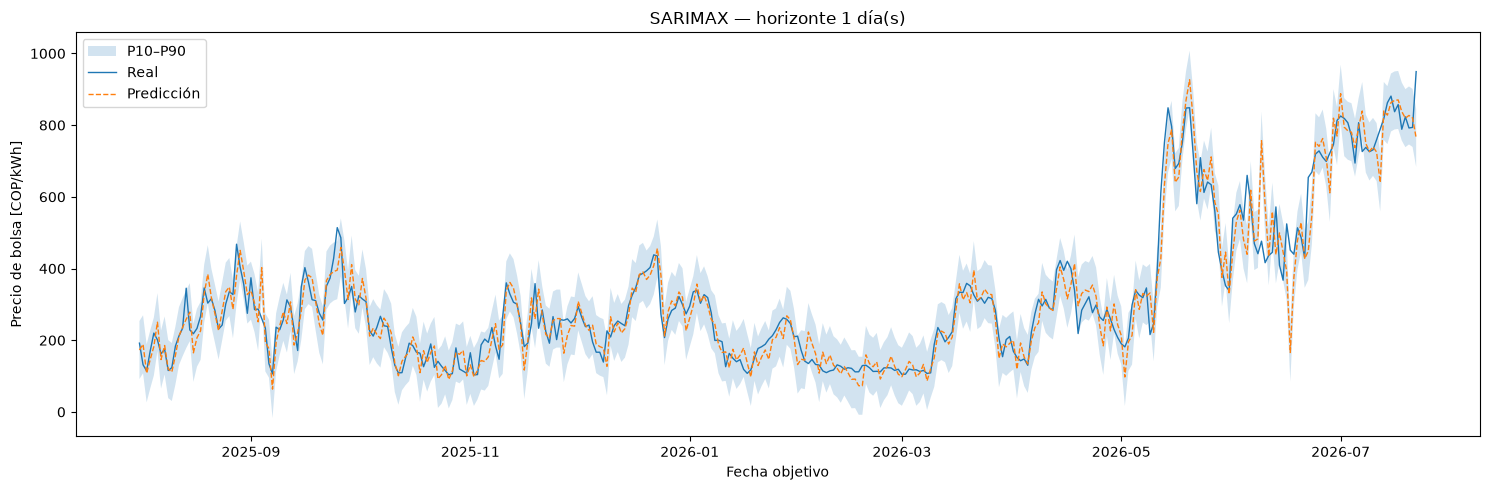

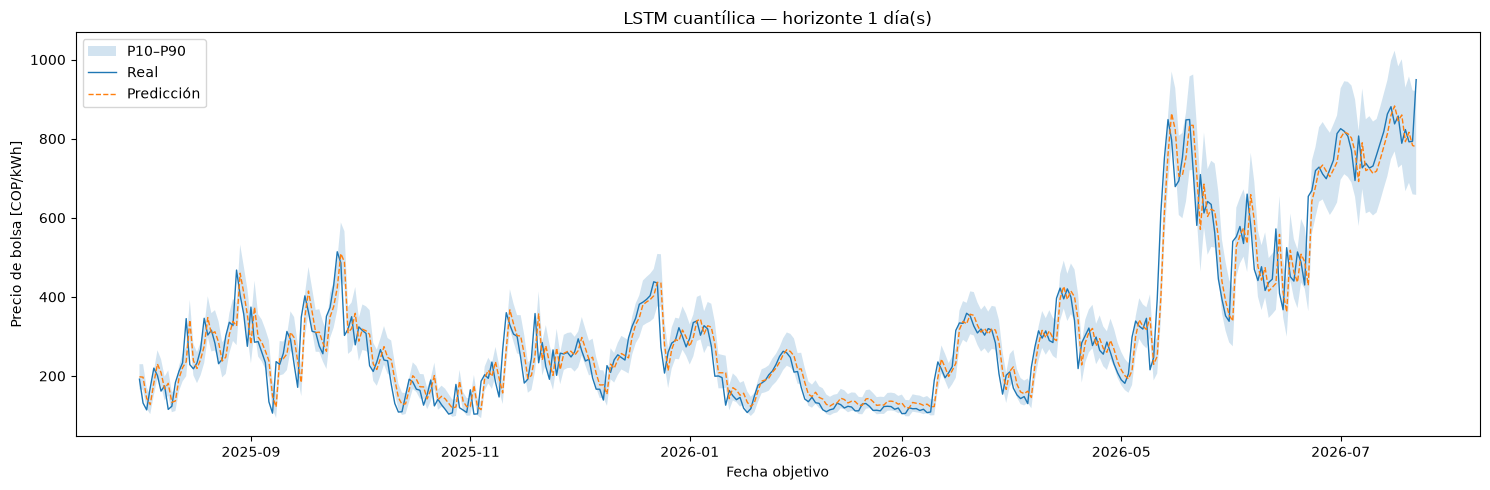

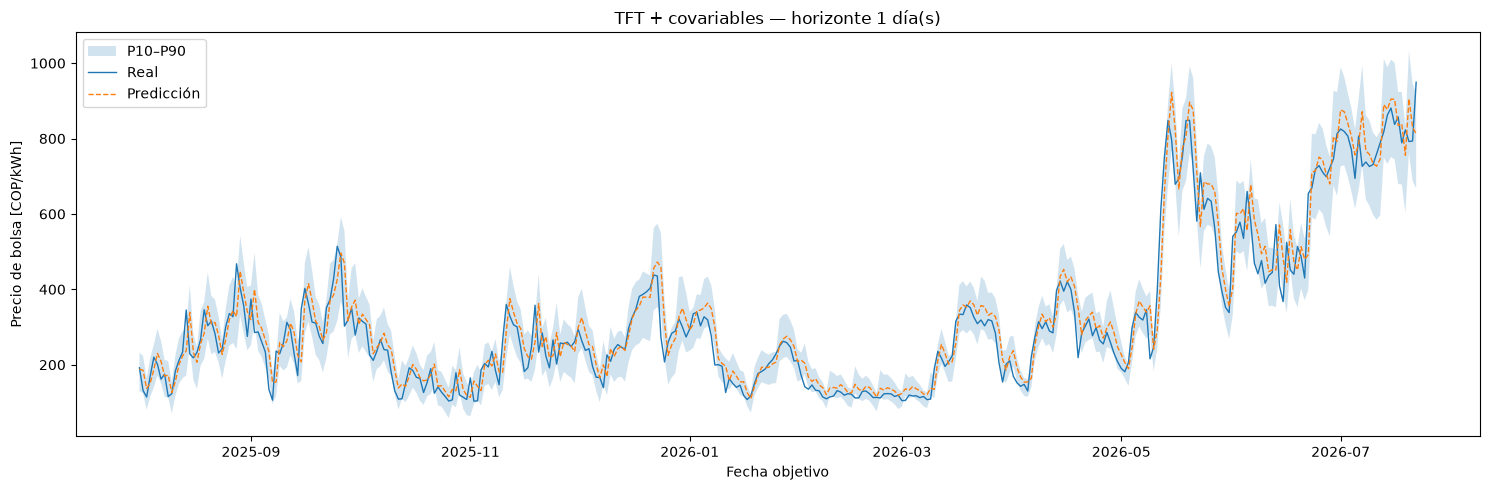

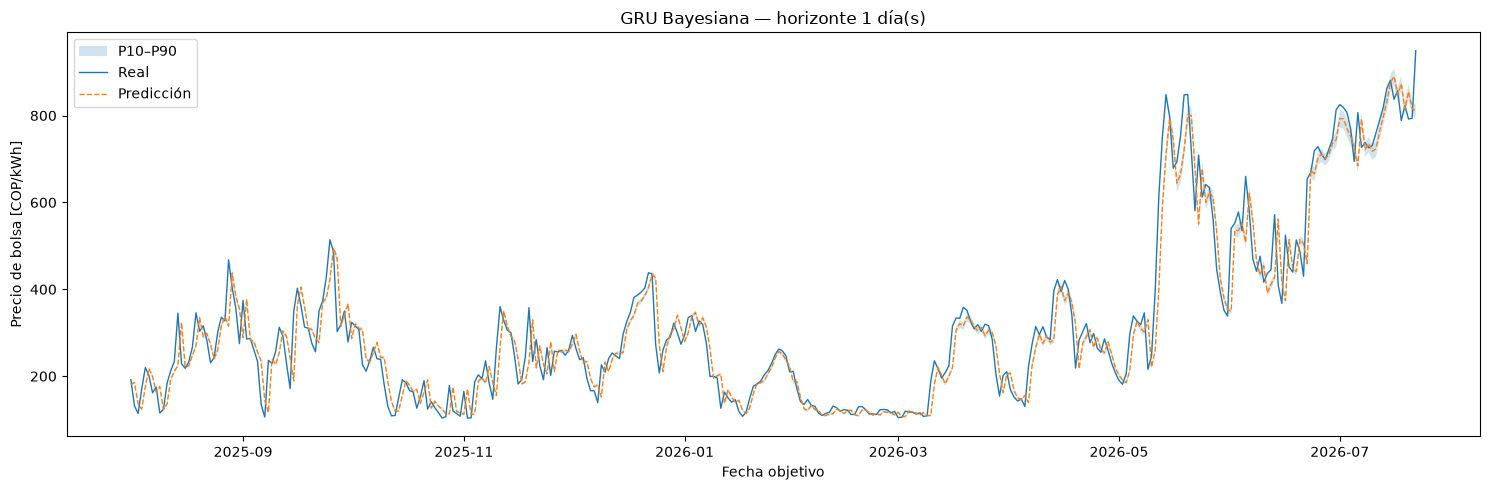

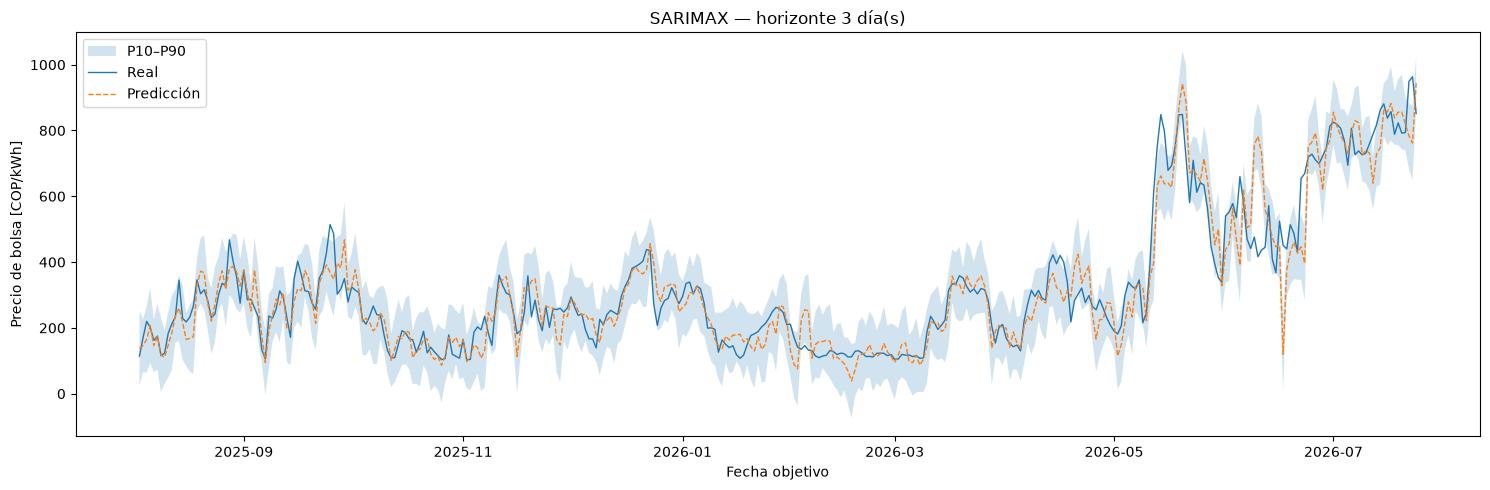

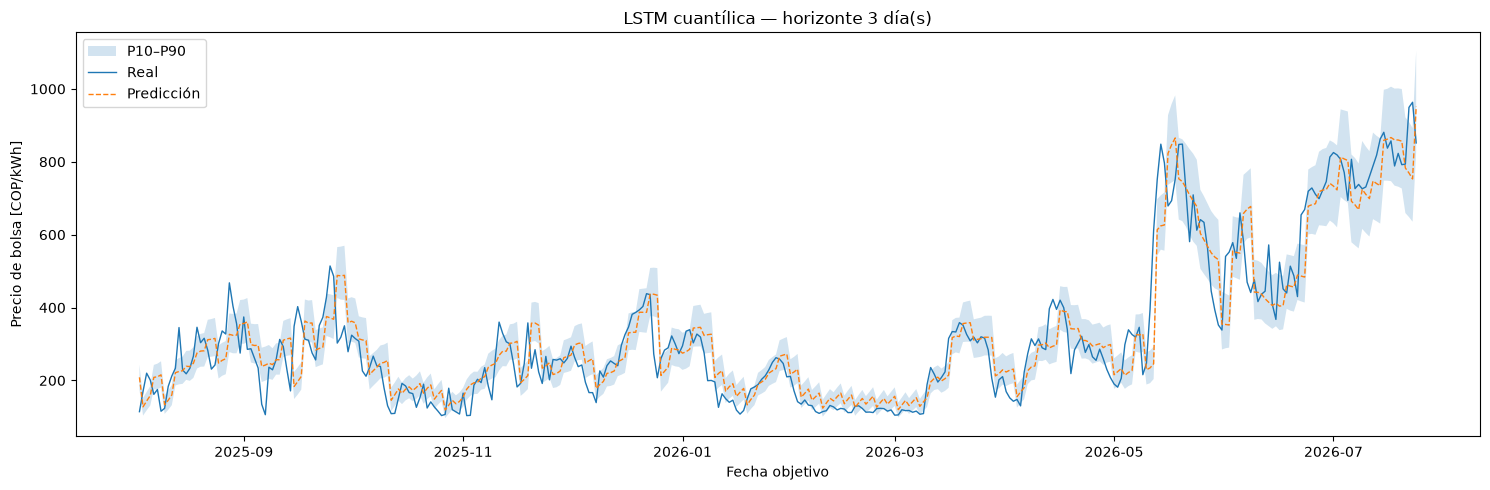

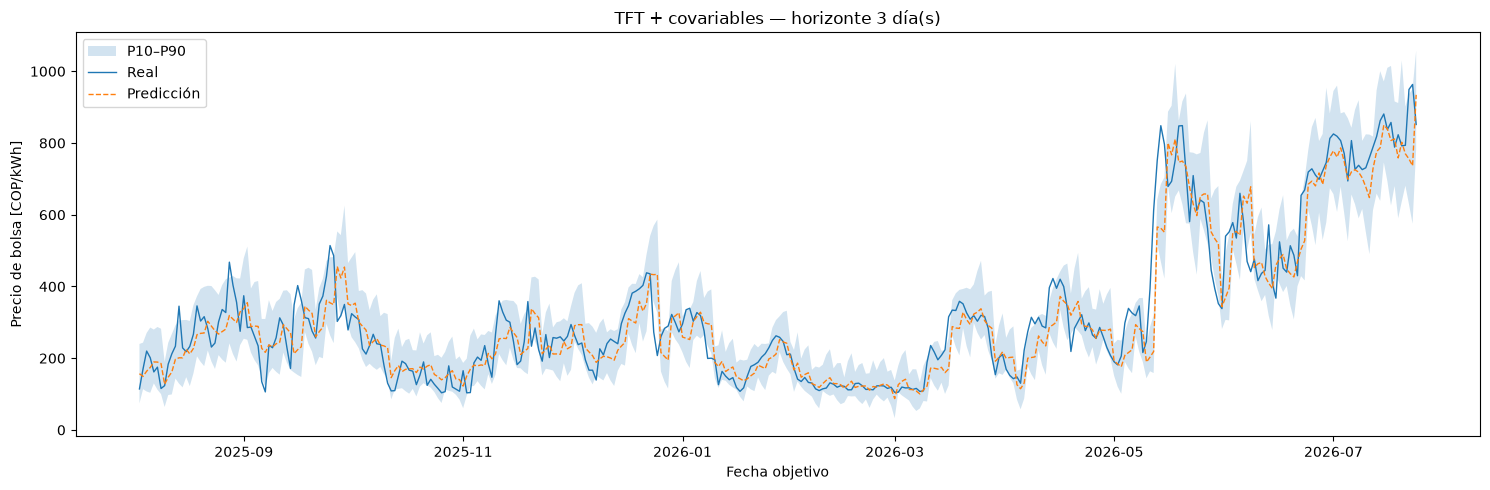

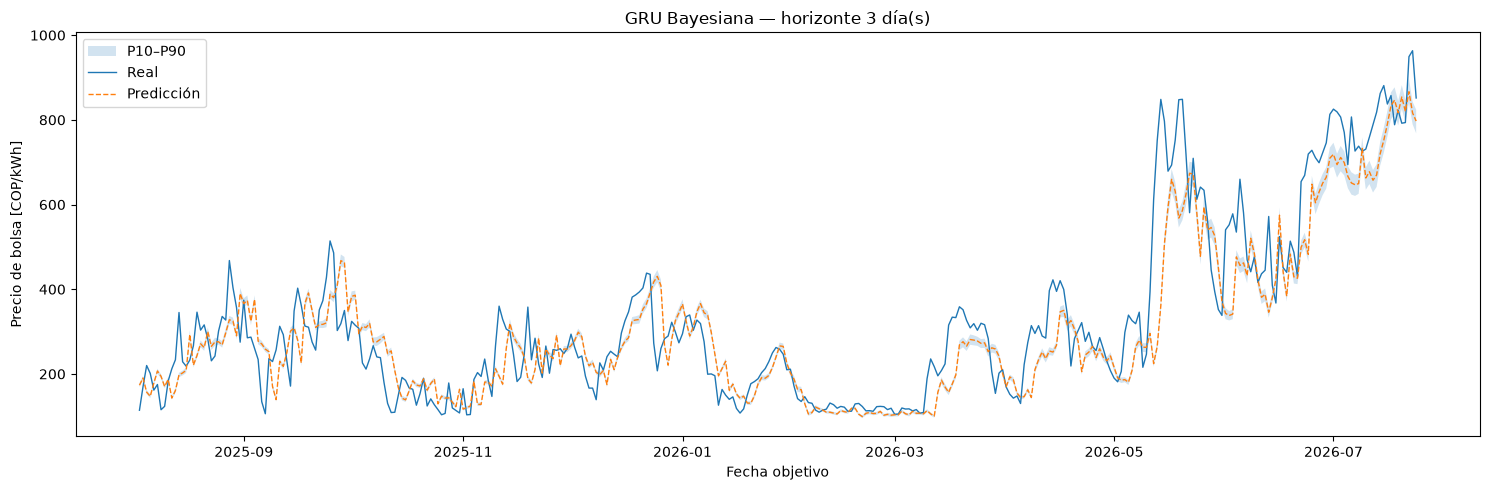

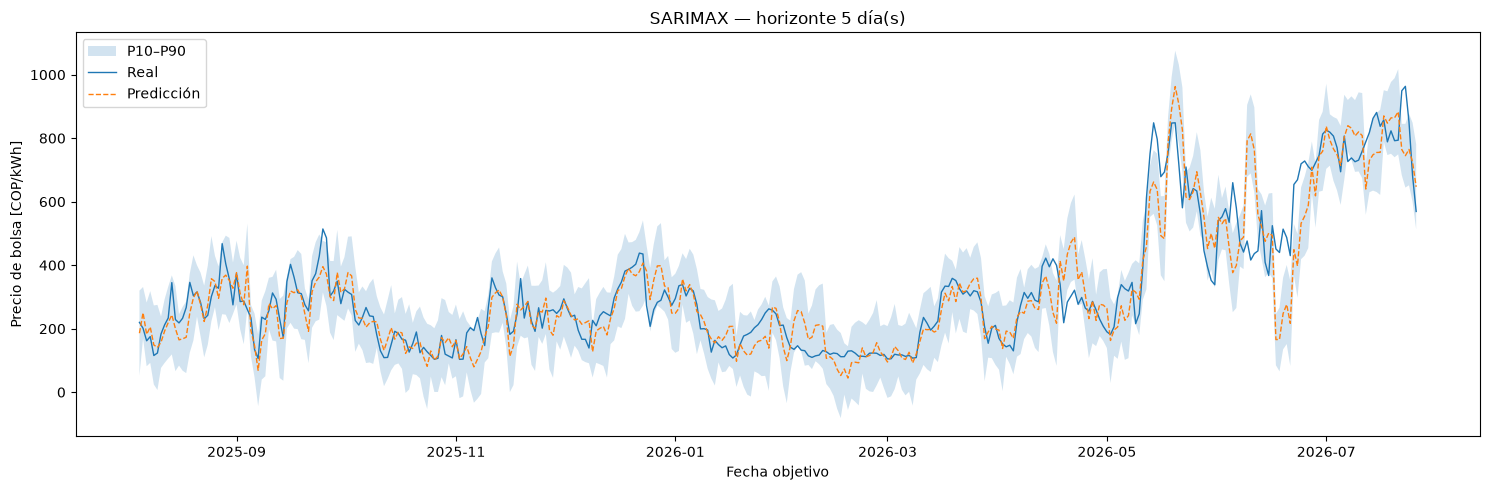

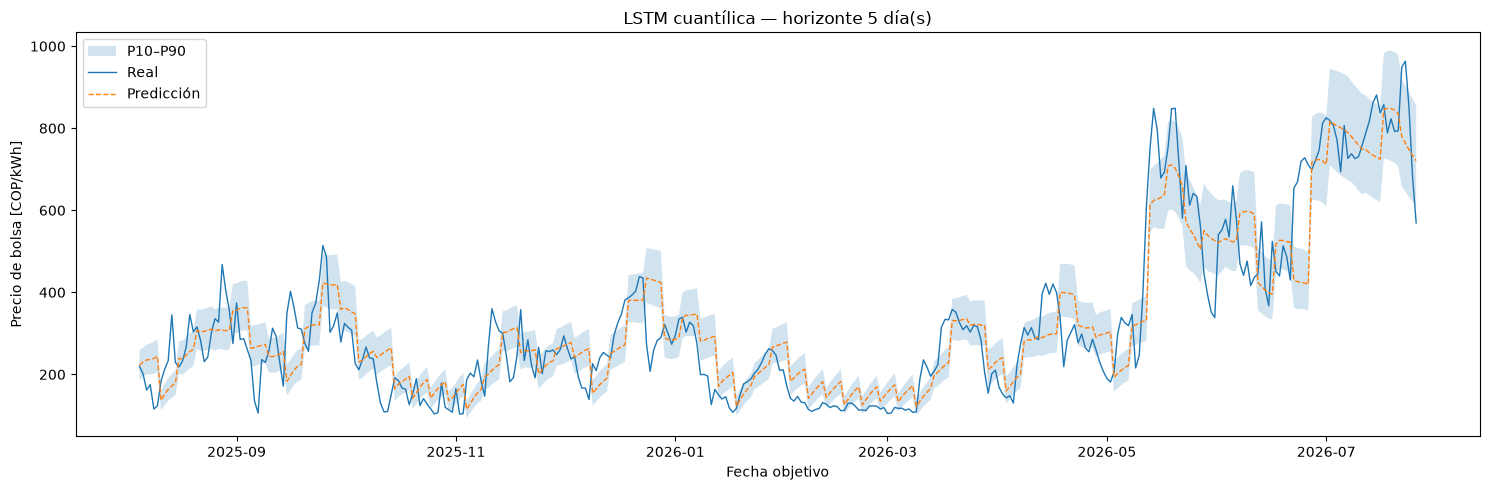

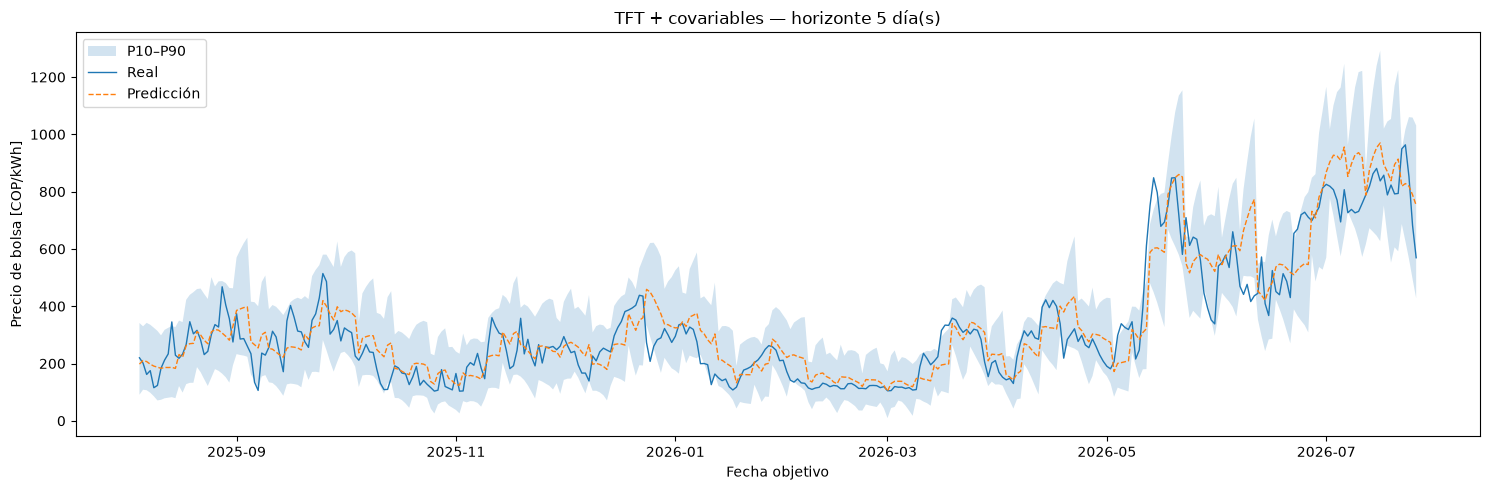

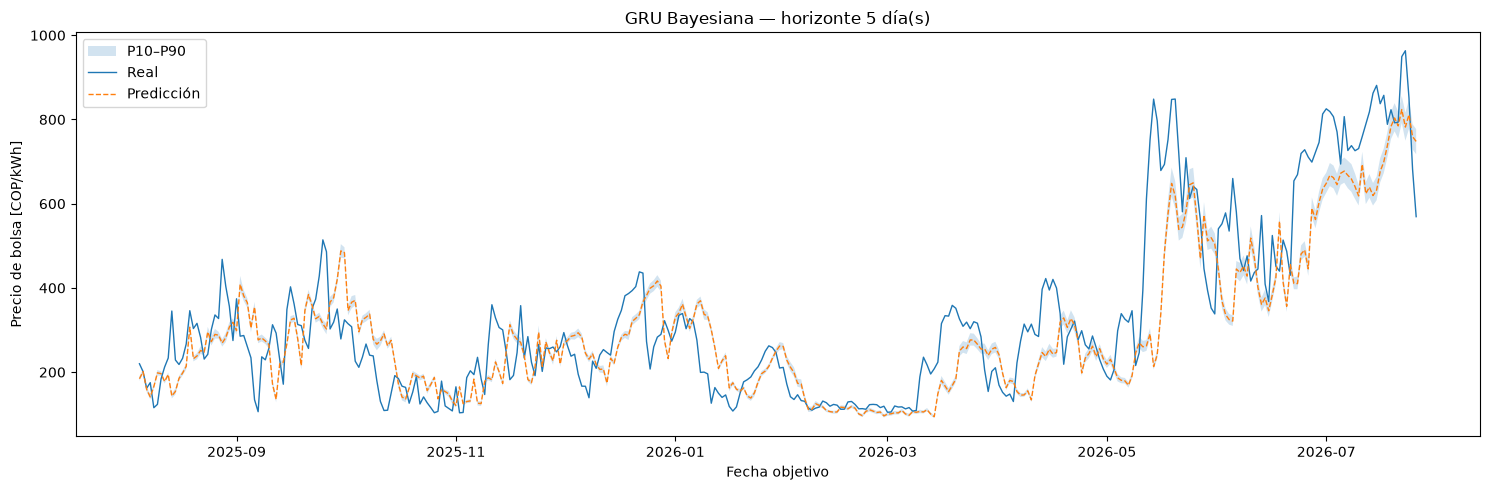

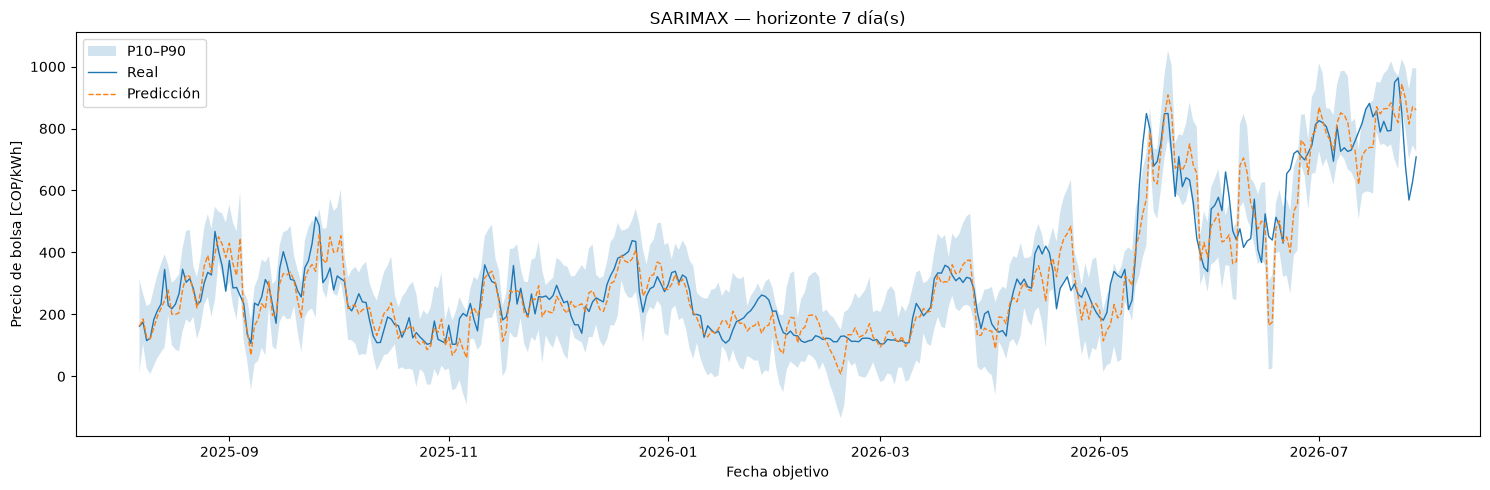

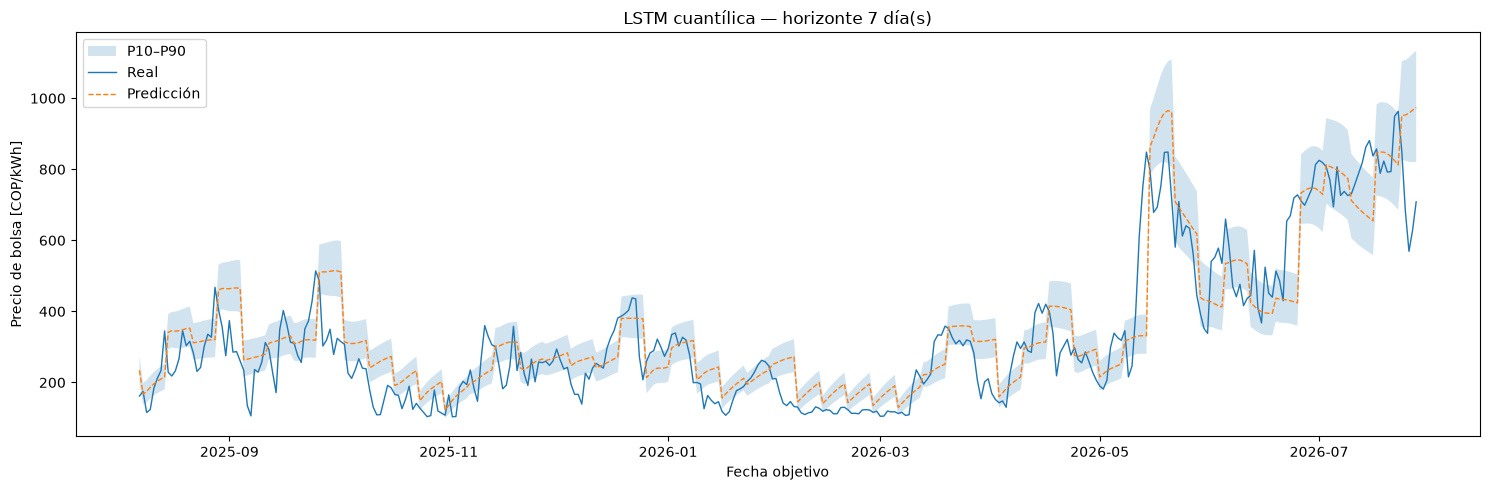

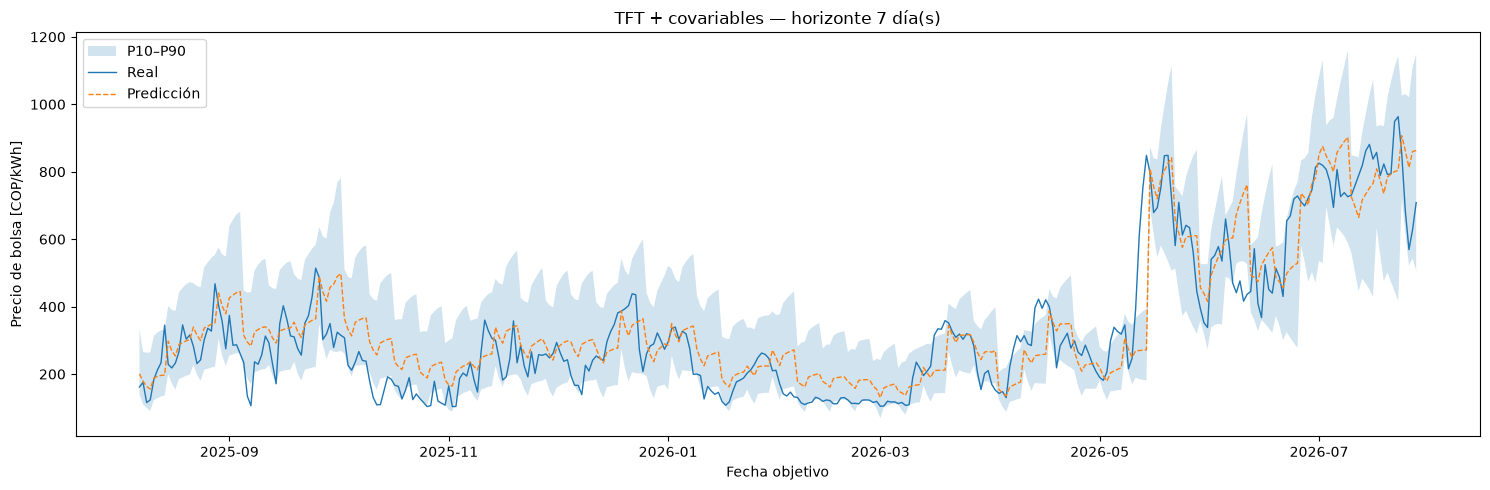

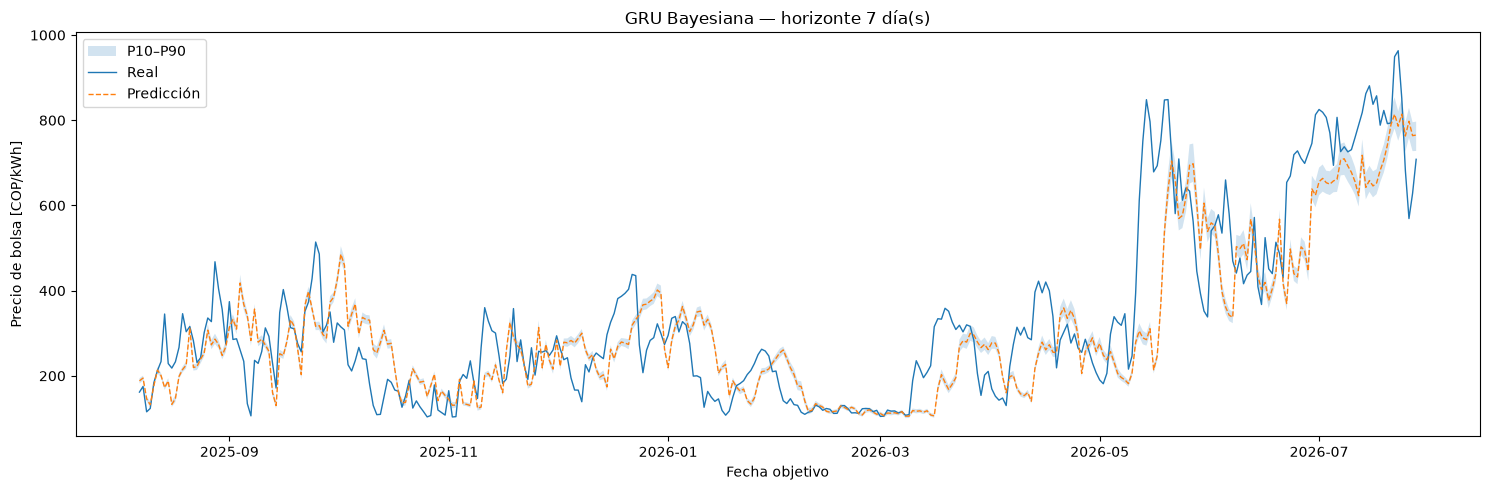

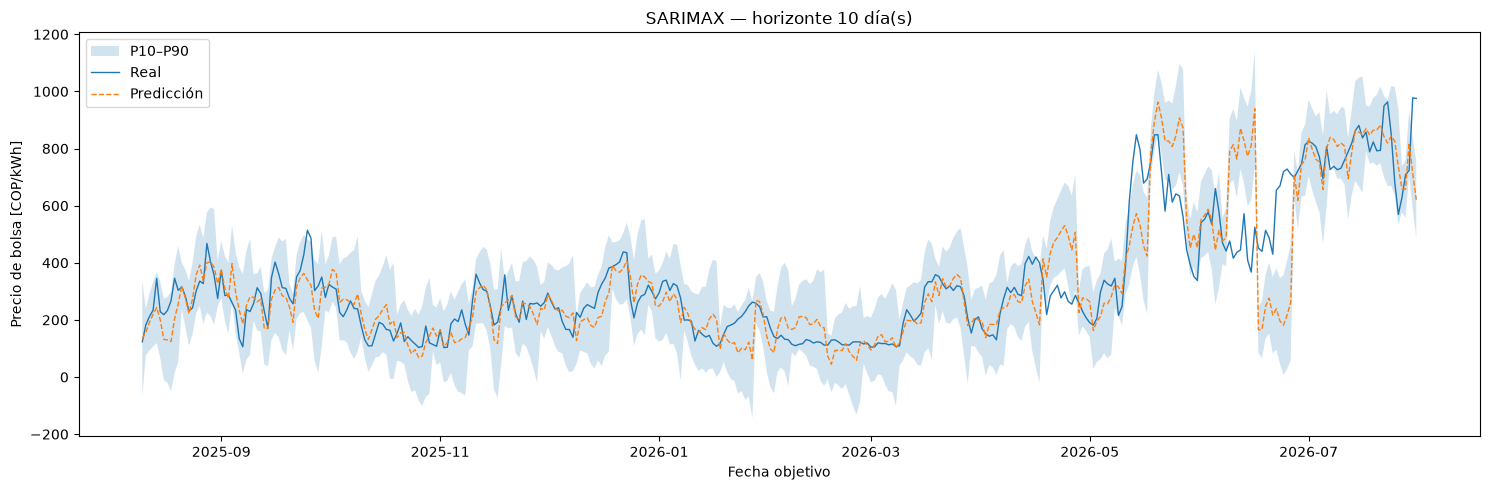

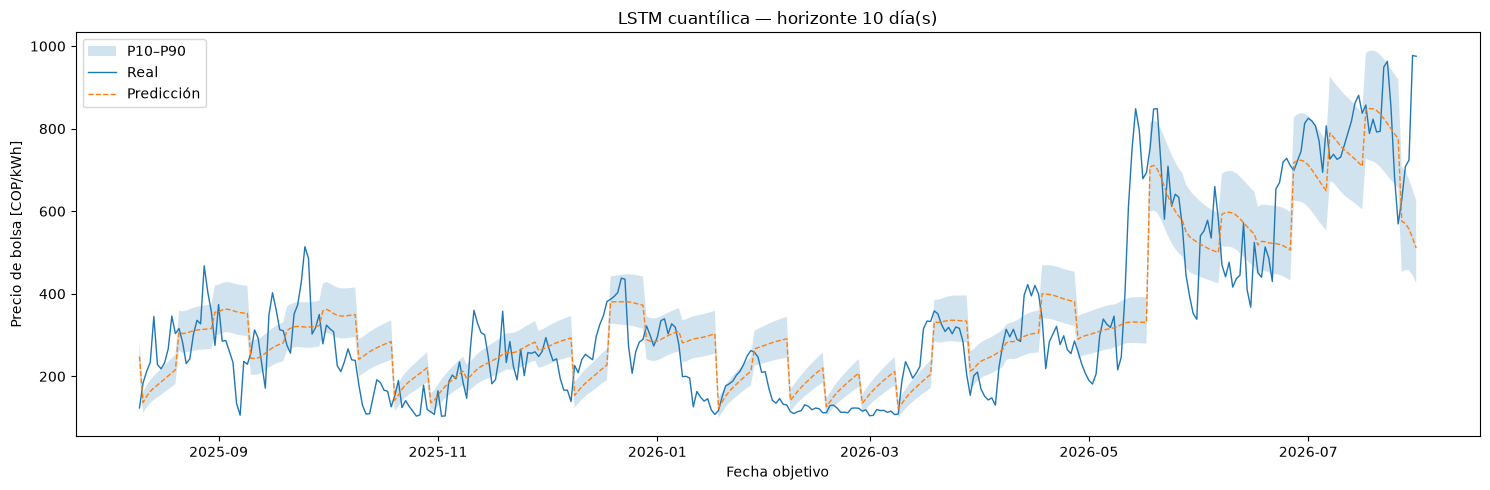

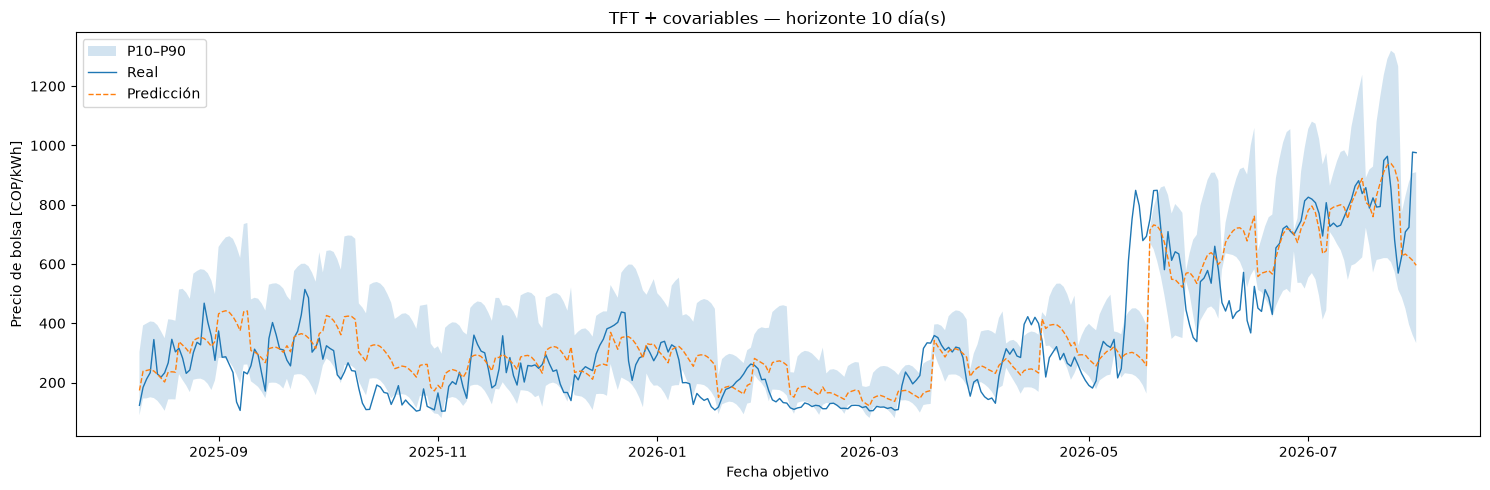

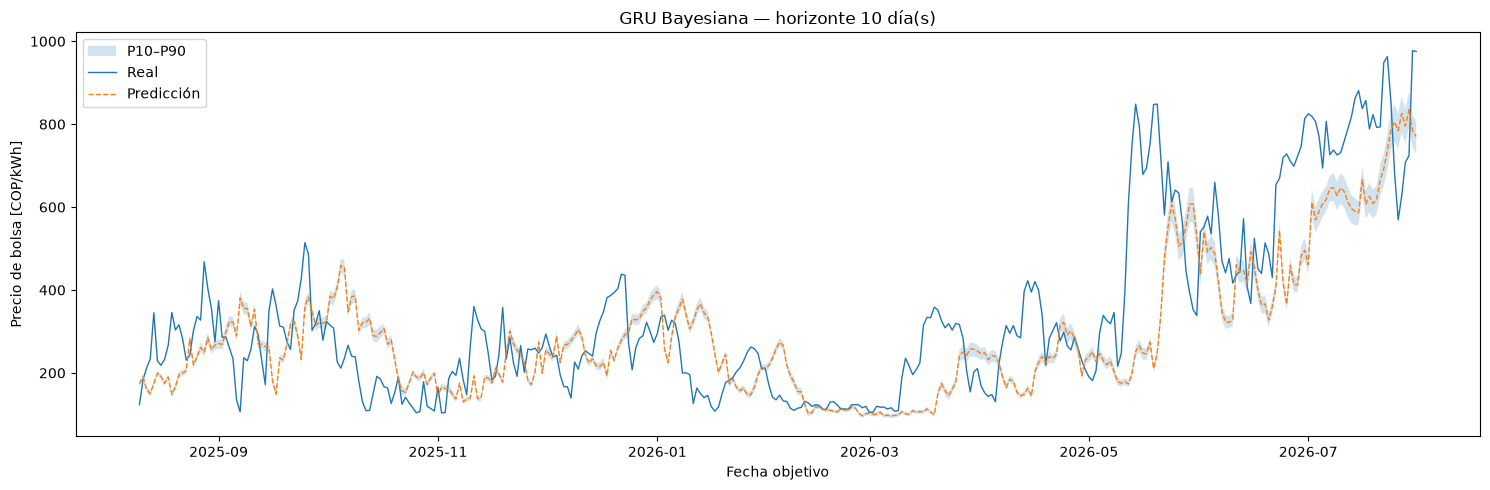

In [12]:
for h in HORIZONTES:
    for modelo in ["SARIMAX","LSTM cuantílica","TFT + covariables","GRU Bayesiana"]:
        key=(modelo,h)
        if key not in resultados_comunes:
            continue
        z=resultados_comunes[key]
        plt.figure(figsize=(15,5))
        plt.fill_between(z.index,z.p10,z.p90,alpha=.20,label="P10–P90")
        plt.plot(z.index,z.real,label="Real",linewidth=1)
        plt.plot(z.index,z.pred,"--",label="Predicción",linewidth=1)
        plt.title(f"{modelo} — horizonte {h} día(s)")
        plt.ylabel("Precio de bolsa [COP/kWh]")
        plt.xlabel("Fecha objetivo")
        plt.legend()
        plt.tight_layout()
        plt.show()

## 9. Comparación puntual conjunta

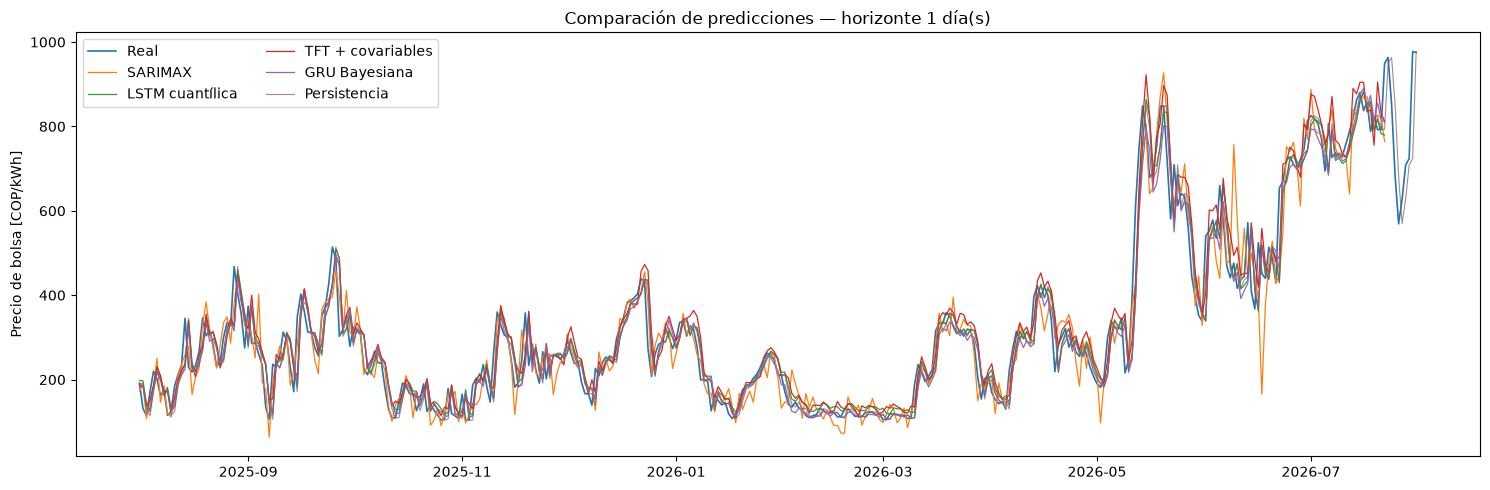

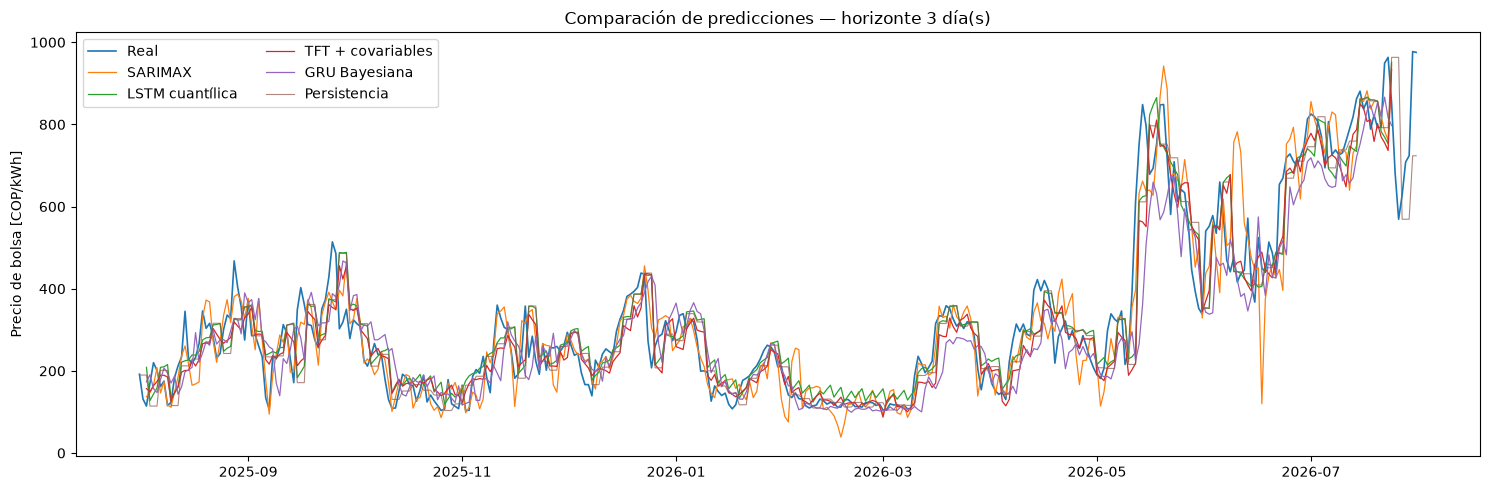

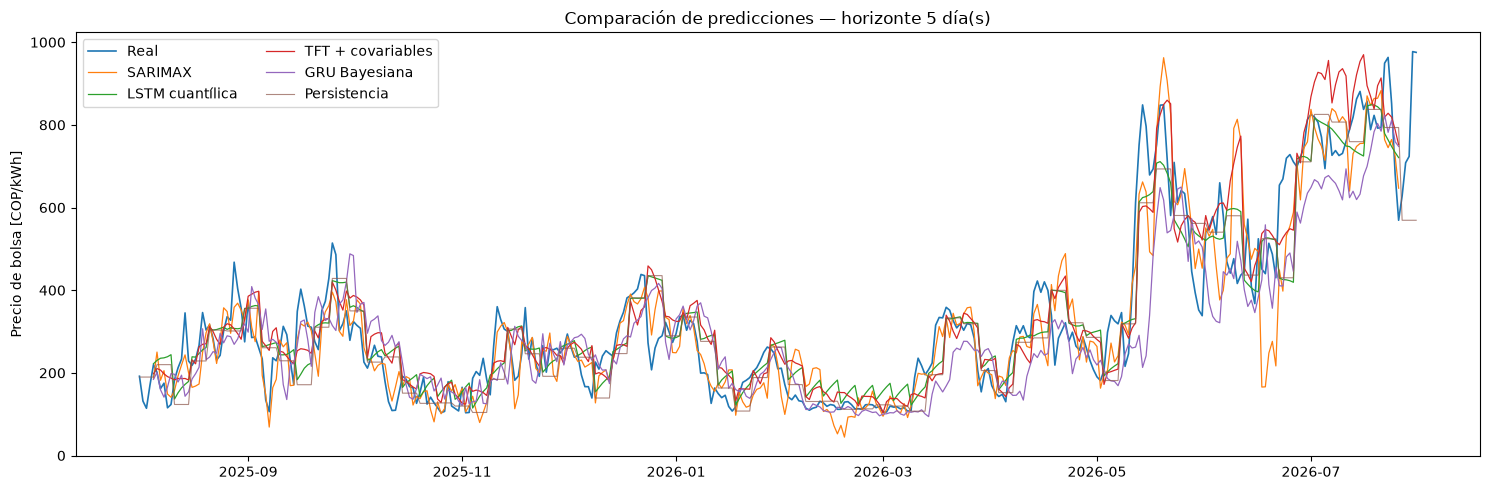

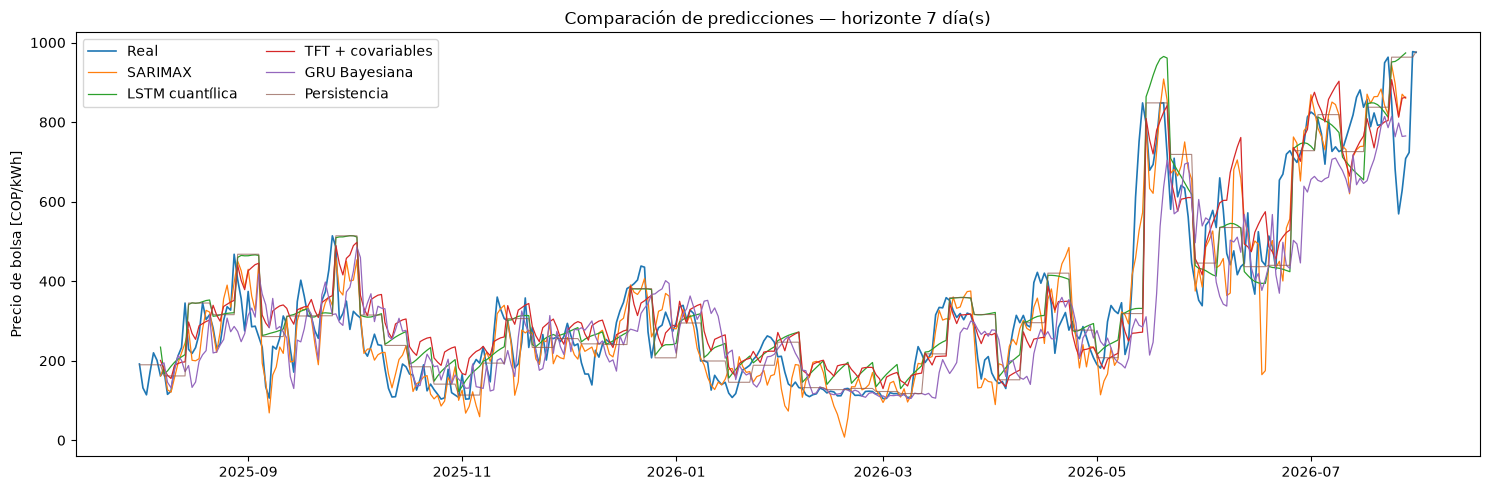

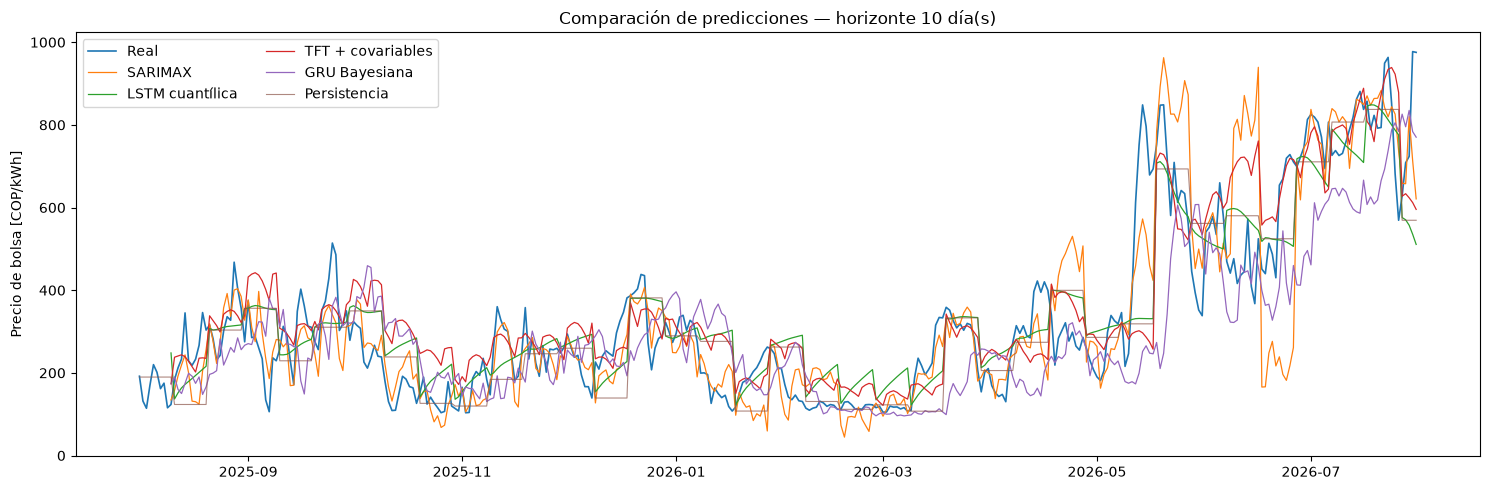

In [13]:
for h in HORIZONTES:
    plt.figure(figsize=(15,5))
    plt.plot(test_data.index,test_data.precio_bolsa if hasattr(test_data,'precio_bolsa') else test_data,
             label="Real",linewidth=1.2)
    for modelo in ["SARIMAX","LSTM cuantílica","TFT + covariables","GRU Bayesiana"]:
        if (modelo,h) in resultados_comunes:
            z=resultados_comunes[(modelo,h)]
            plt.plot(z.index,z.pred,label=modelo,linewidth=.9)
    p=persistencia[h]
    plt.plot(p.index,p.values,label="Persistencia",linewidth=.8,alpha=.7)
    plt.title(f"Comparación de predicciones — horizonte {h} día(s)")
    plt.ylabel("Precio de bolsa [COP/kWh]")
    plt.legend(ncol=2)
    plt.tight_layout()
    plt.show()

## 10. Calibración UCT

In [14]:
if UCT_OK:
    for h in HORIZONTES:
        for modelo in ["SARIMAX","LSTM cuantílica","TFT + covariables","GRU Bayesiana"]:
            if (modelo,h) not in resultados_comunes:
                continue
            z=resultados_comunes[(modelo,h)]
            try:
                uct.viz.plot_calibration(
                    z.pred.to_numpy(),z["std"].to_numpy(),z.real.to_numpy()
                )
                plt.title(f"Calibración UCT — {modelo} — h={h}")
                plt.tight_layout()
                plt.show()
            except Exception as e:
                print(f"No se pudo dibujar calibración {modelo} h={h}: {e}")
else:
    print("Instala uncertainty-toolbox para generar estas gráficas.")

Instala uncertainty-toolbox para generar estas gráficas.


## 11. Tablas, exportaciones y curvas de deterioro

Se guardan resultados en `reports/comparacion_probabilistica_h1_3_5_7_10/`, incluidas tablas, predicciones por modelo/horizonte y curvas de RMSE, MAE, cobertura, ancho e interval score.

RANKING PUNTUAL


,Modelo,Horizonte,MAE,RMSE,MAPE (%),sMAPE (%),R²,Sesgo
3,GRU Bayesiana,1,36.6309,53.3944,12.9066,12.8221,0.9287,-5.7229
2,TFT + covariables,1,39.8552,54.3113,14.7330,13.7064,0.9262,15.6459
0,SARIMAX,1,38.1358,54.6339,13.9940,14.0404,0.9253,-2.5236
1,LSTM cuantílica,1,39.9097,55.6679,14.8259,14.2488,0.9225,2.7284
20,Persistencia,1,38.9837,55.9654,13.7216,13.6502,0.9216,-2.1333
4,SARIMAX,3,47.5626,69.6930,16.8370,16.8833,0.8837,-3.5026
6,TFT + covariables,3,50.7427,71.4486,17.5594,17.3100,0.8778,-11.3357
5,LSTM cuantílica,3,54.8721,74.8173,20.7676,19.0406,0.8660,4.1341
21,Persistencia,3,53.9948,75.5954,19.0542,18.5756,0.8632,-5.0944
7,GRU Bayesiana,3,63.4951,89.8269,21.2152,21.2365,0.8068,-23.6901


RANKING / DIAGNÓSTICO PROBABILÍSTICO


,Modelo,Horizonte,Cobertura 80% (%),Ancho P10-P90,Interval score 80%,CRPS,NLL
2,TFT + covariables,1,82.0225,132.2242,175.8412,NaN,NaN
1,LSTM cuantílica,1,71.3483,106.5545,205.5170,NaN,NaN
0,SARIMAX,1,89.3258,161.8360,210.0447,NaN,NaN
3,GRU Bayesiana,1,14.3258,13.4833,318.4817,NaN,NaN
6,TFT + covariables,3,83.1461,169.0645,232.5547,NaN,NaN
4,SARIMAX,3,88.7640,196.1249,258.0819,NaN,NaN
5,LSTM cuantílica,3,55.3371,108.2435,296.6402,NaN,NaN
7,GRU Bayesiana,3,7.5843,20.2633,560.0310,NaN,NaN
10,TFT + covariables,5,91.0112,282.3266,312.6831,NaN,NaN
8,SARIMAX,5,86.2360,221.2563,313.9686,NaN,NaN


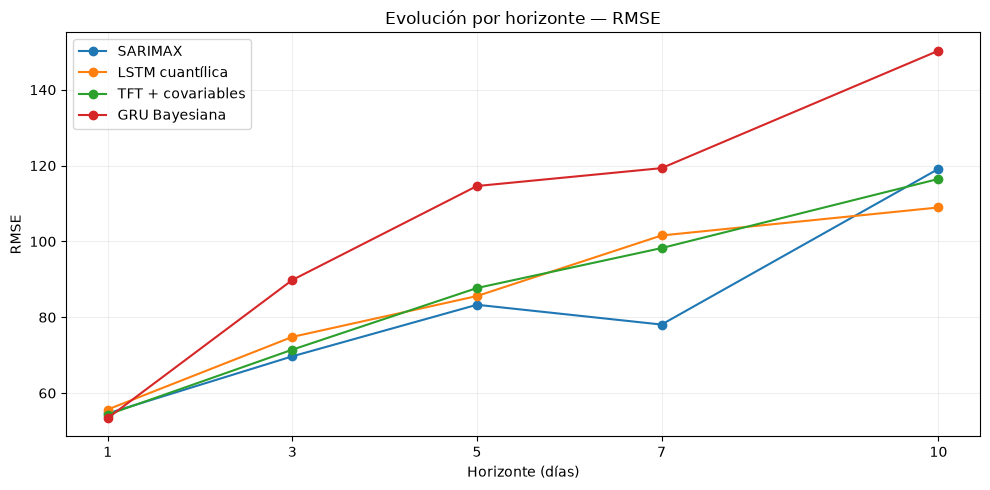

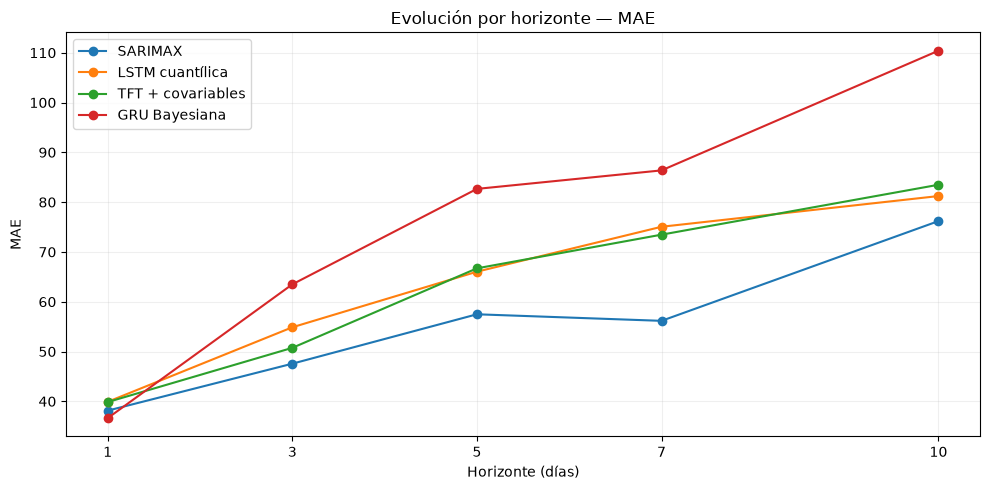

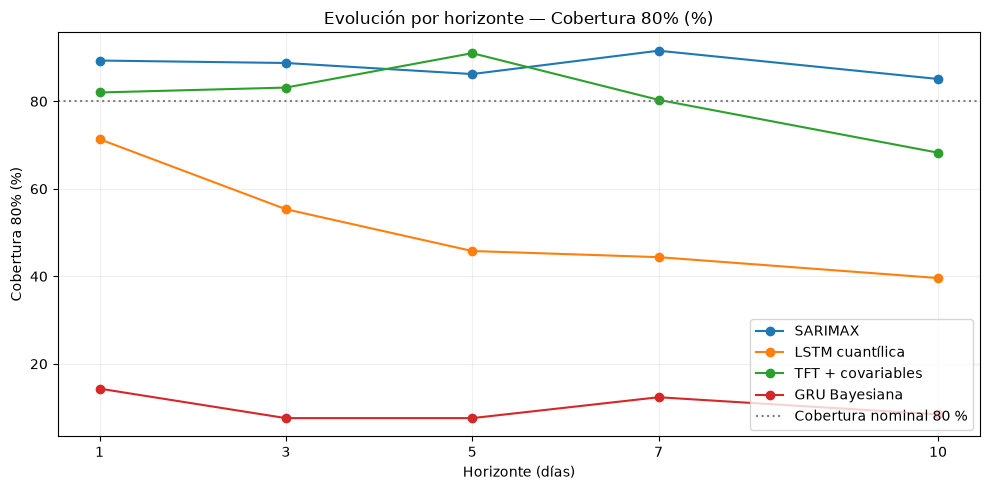

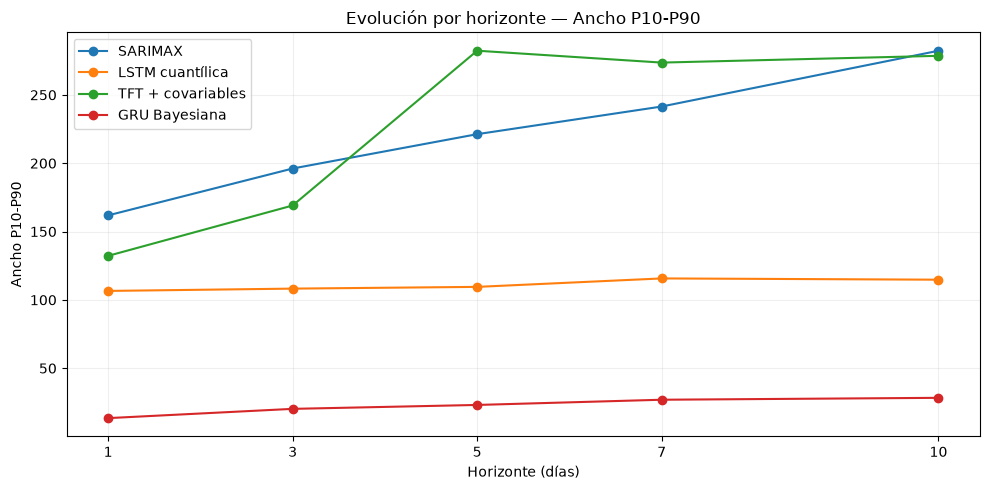

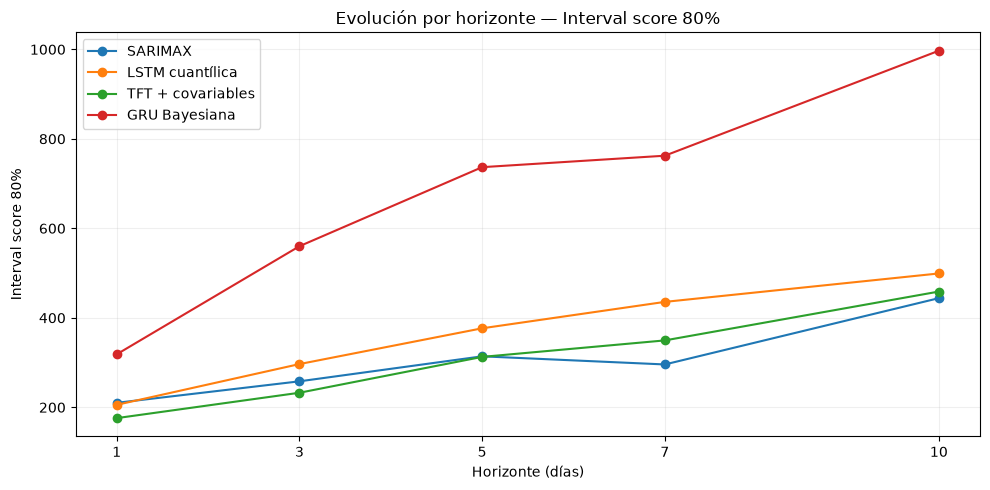

Resultados guardados en: /Users/maguverm/Documents/tesis-bolsa/reports/comparacion_probabilistica_h1_3_5_7_10


In [15]:
cols_punt=['Modelo','Horizonte','MAE','RMSE','MAPE (%)','sMAPE (%)','R²','Sesgo']
cols_prob=['Modelo','Horizonte','Cobertura 80% (%)','Ancho P10-P90','Interval score 80%',
           'MACE','RMSCE','Sharpness UCT','CRPS','NLL']
print('RANKING PUNTUAL')
display(tabla_final[[c for c in cols_punt if c in tabla_final.columns]].sort_values(['Horizonte','RMSE']).round(4))
prob=tabla_final[tabla_final.Modelo!='Persistencia'].copy()
cols=[c for c in cols_prob if c in prob.columns]
criterio='Interval score 80%' if 'Interval score 80%' in cols else 'RMSE'
print('RANKING / DIAGNÓSTICO PROBABILÍSTICO')
display(prob[cols].sort_values(['Horizonte',criterio],na_position='last').round(4))
tabla_final.to_csv(REPORTS/'tabla_comparativa_probabilistica.csv',index=False)
tabla_final.to_parquet(REPORTS/'tabla_comparativa_probabilistica.parquet',index=False)
for (modelo,h),z in resultados_comunes.items():
    nombre=modelo.lower().replace(' ','_').replace('+','mas')
    z.to_parquet(REPORTS/f'pred_{nombre}_h{h}.parquet')
# Curvas de desempeño por horizonte
for metrica in ['RMSE','MAE','Cobertura 80% (%)','Ancho P10-P90','Interval score 80%']:
    fig,ax=plt.subplots(figsize=(10,5))
    for modelo in ['SARIMAX','LSTM cuantílica','TFT + covariables','GRU Bayesiana']:
        zz=tabla_final[tabla_final.Modelo.eq(modelo)].sort_values('Horizonte')
        ax.plot(zz.Horizonte,zz[metrica],marker='o',label=modelo)
    if metrica=='Cobertura 80% (%)': ax.axhline(80,color='gray',ls=':',label='Cobertura nominal 80 %')
    ax.set_xticks(HORIZONTES); ax.set_xlabel('Horizonte (días)'); ax.set_ylabel(metrica)
    ax.set_title(f'Evolución por horizonte — {metrica}'); ax.grid(alpha=.2); ax.legend()
    fig.tight_layout()
    fig.savefig(REPORTS/f'curva_{metrica.lower().replace(" ","_").replace("%", "pct")}.png',dpi=180)
    plt.show()
print('Resultados guardados en:',REPORTS)


## Lectura recomendada para la tesis

La comparación debe separar dos preguntas:

1. **¿Qué modelo predice mejor el nivel del precio?**  
   Se responde con MAE, RMSE, MAPE, sMAPE y R², contrastando además con Persistencia.

2. **¿Qué modelo representa mejor su propia incertidumbre?**  
   Se responde con cobertura, ancho de P10–P90, calibración, sharpness y proper scoring rules.

Un modelo probabilístico no debe considerarse superior solo por producir bandas. Una banda útil debe ser simultáneamente **razonablemente calibrada y suficientemente estrecha**, manteniendo buena precisión puntual.

### Origen de la incertidumbre
- SARIMAX: distribución predictiva del modelo state-space.
- LSTM: cuantiles aprendidos por pinball loss.
- TFT + covariables: cuantiles probabilísticos nativos de GluonTS.
- GRU Bayesiana: variabilidad empírica de múltiples forward passes con pesos bayesianos muestreados.